ESM-2 **outputs**

In [43]:
import os
import re
import pandas as pd
import torch 
import esm
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure graphs render inline inside the notebook
%matplotlib inline

# Create the target directory for all outputs
OUTPUT_DIR = "Analysis_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configure CPU Threading for HPC multiprocessing
NUM_THREADS = 16
torch.set_num_threads(NUM_THREADS)
print(f"[+] PyTorch configured to use {NUM_THREADS} CPU threads.")
print(f"[+] Outputs will be saved to: {OUTPUT_DIR}/")

[+] PyTorch configured to use 16 CPU threads.
[+] Outputs will be saved to: Analysis_results/


In [34]:
FASTA_FILE = "PfK13_WT_726.fasta"

def load_sequence(fasta_path):
    if not os.path.isfile(fasta_path):
        import requests
        print(f"[!] {fasta_path} not found locally. Downloading from UniProt...")
        res = requests.get("https://rest.uniprot.org/uniprotkb/Q8IDQ2.fasta")
        with open(fasta_path, "w") as f:
            f.write(res.text)

    with open(fasta_path, "r") as f:
        lines = [line.strip() for line in f if not line.startswith(">")]
    seq = "".join(lines).upper()
    if len(seq) != 726:
        raise ValueError(f"Sequence length is {len(seq)}, expected 726 aa.")
    return seq

wt_seq = load_sequence(FASTA_FILE)
print(f"[+] Loaded PfK13 reference sequence ({len(wt_seq)} amino acids).")

[!] PfK13_WT_726.fasta not found locally. Downloading from UniProt...
[+] Loaded PfK13 reference sequence (726 amino acids).


In [35]:
print("[+] Loading Meta ESM-2 (650M parameters)...")
model, alphabet = esm.pretrained.esm2_t33_650M_UR50D()
batch_converter = alphabet.get_batch_converter()
model.eval()

data = [("PfK13_WT", wt_seq)]
_, _, tokens = batch_converter(data)

print("[+] Executing single forward pass through ESM-2...")
with torch.no_grad():
    results = model(tokens, repr_layers=[model.num_layers], return_contacts=False)
    logits = results["logits"][0]

# Precompute log-probabilities across vocabulary for each position
log_probs = torch.log_softmax(logits, dim=-1)
print("[✓] Forward pass complete. Logits cached in memory.")

[+] Loading Meta ESM-2 (650M parameters)...
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t33_650M_UR50D.pt" to /home/adedayoadedisa/.cache/torch/hub/checkpoints/esm2_t33_650M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t33_650M_UR50D-contact-regression.pt" to /home/adedayoadedisa/.cache/torch/hub/checkpoints/esm2_t33_650M_UR50D-contact-regression.pt
[+] Executing single forward pass through ESM-2...
[✓] Forward pass complete. Logits cached in memory.


In [36]:
CSV_FILE = "K13 mutations and prevalence.csv"
df_raw = pd.read_csv(CSV_FILE)
unique_muts = sorted(df_raw["Mutation"].dropna().str.strip().unique())
print(f"[+] Scoring {len(unique_muts)} variants from precomputed logits...")

scores = []
for mut in unique_muts:
    m = re.match(r"^([A-Z])(\d+)([A-Z])$", mut)
    if not m:
        continue
    wt_aa, pos_str, mut_aa = m.groups()
    pos = int(pos_str)

    seq_idx = pos - 1
    actual_wt = wt_seq[seq_idx]
    if actual_wt != wt_aa:
        print(f"[!] Mismatch at {mut}: expected {wt_aa}, found {actual_wt}. Skipping.")
        continue

    token_idx = pos
    idx_wt = alphabet.get_idx(wt_aa)
    idx_mut = alphabet.get_idx(mut_aa)

    # Log-Likelihood Ratio (LLR)
    llr = (log_probs[token_idx, idx_mut] - log_probs[token_idx, idx_wt]).item()

    if llr < -7.0:
        prediction = "Severely Disruptive"
    elif llr < -4.0:
        prediction = "Moderately Disruptive"
    else:
        prediction = "Tolerated / Neutral"

    scores.append({
        "Mutation": mut,
        "Position": pos,
        "WT_AA": wt_aa,
        "Mutant_AA": mut_aa,
        "ESM2_LLR_Score": round(llr, 4),
        "Evolutionary_Disruption": prediction
    })

df_scores = pd.DataFrame(scores).sort_values(by="ESM2_LLR_Score", ascending=True)
df_merged = pd.merge(df_raw, df_scores, on="Mutation", how="left")

# Save directly into the Analysis_results folder
csv_out_path = os.path.join(OUTPUT_DIR, "esm2_k13_variant_scores.csv")
df_merged.to_csv(csv_out_path, index=False)
print(f"[✓] Data saved to: {csv_out_path}")

# Display the formatted dataframe directly below the cell
display(df_scores[["Mutation", "Position", "ESM2_LLR_Score", "Evolutionary_Disruption"]])

[+] Scoring 32 variants from precomputed logits...
[✓] Data saved to: Analysis_results/esm2_k13_variant_scores.csv


,Mutation,Position,ESM2_LLR_Score,Evolutionary_Disruption
11,G545V,545,-14.5941,Severely Disruptive
25,T685K,685,-13.7596,Severely Disruptive
10,G496V,496,-10.8346,Severely Disruptive
4,D512Y,512,-10.0206,Severely Disruptive
23,S600Y,600,-9.4453,Severely Disruptive
9,G453C,453,-9.2136,Severely Disruptive
31,W706C,706,-8.0068,Severely Disruptive
26,V487E,487,-6.9376,Moderately Disruptive
6,E602D,602,-6.7132,Moderately Disruptive
1,A582P,582,-6.3520,Moderately Disruptive


/tmp/ipykernel_4049040/3880844939.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_scores, x="Mutation", y="ESM2_LLR_Score", palette="magma")


[✓] Graph saved to: Analysis_results/ESM2_Evolutionary_Scoring_600dpi.png


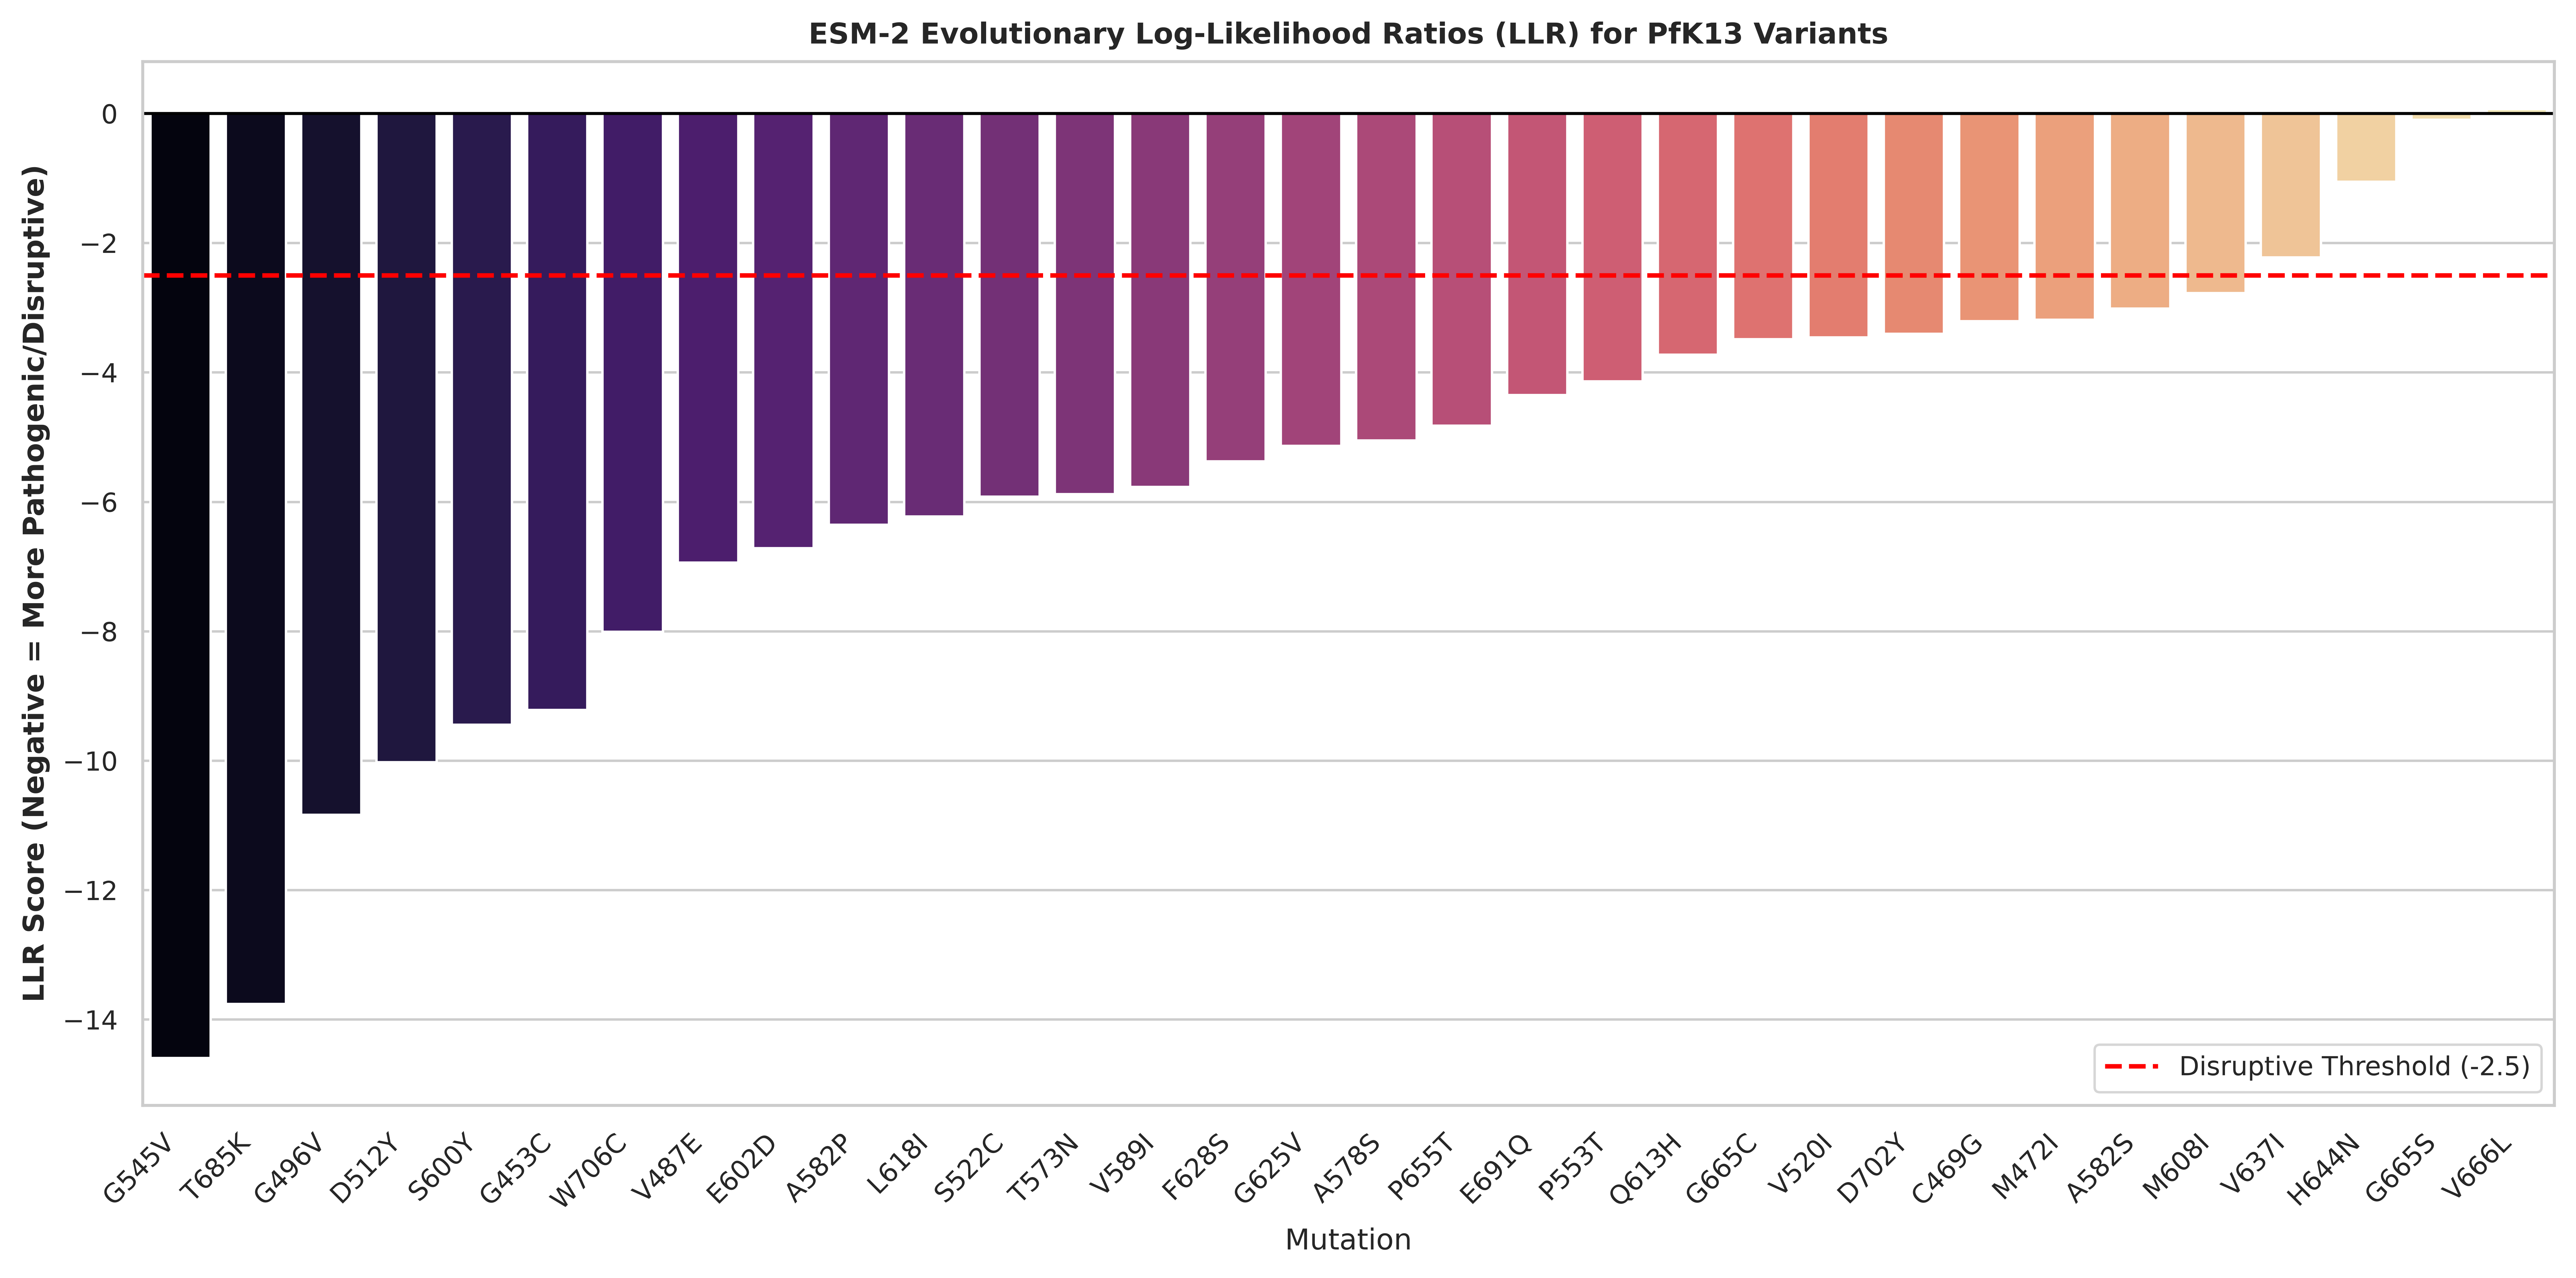

In [37]:
# Global Plotting Configuration (600 DPI)
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
sns.set_theme(style="whitegrid", context="paper")

plt.figure(figsize=(12, 6))
sns.barplot(data=df_scores, x="Mutation", y="ESM2_LLR_Score", palette="magma")

# Add threshold lines
plt.axhline(0, color='black', linewidth=1)
plt.axhline(-2.5, color='red', linewidth=1.5, linestyle='--', label='Disruptive Threshold (-2.5)')

plt.title("ESM-2 Evolutionary Log-Likelihood Ratios (LLR) for PfK13 Variants", weight="bold")
plt.ylabel("LLR Score (Negative = More Pathogenic/Disruptive)", weight="bold")
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()

# Save High-Res Image to the Analysis_results folder
graph_out_path = os.path.join(OUTPUT_DIR, "ESM2_Evolutionary_Scoring_600dpi.png")
plt.savefig(graph_out_path)
print(f"[✓] Graph saved to: {graph_out_path}")

# Render image inline in the notebook
plt.show()

ESM2_Geographic_Prevalence 

In [63]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

OUTPUT_DIR = "Analysis_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load the dataset
csv_path = os.path.join(OUTPUT_DIR, "esm2_k13_variant_scores.csv")
if not os.path.exists(csv_path):
    csv_path = "esm2_k13_variant_scores.csv"
df = pd.read_csv(csv_path)

# 2. Consolidate Geography & Prevalence per Mutation
# Format each row as "State (Prev%)"
df['Geo_Prev'] = df['State'] + " (" + df['Prevalence'].astype(str) + "%)"

# Group by Mutation and ESM2 Score to get exactly ONE row per mutation
# Join all the state strings with a comma
df_grouped = df.groupby(['Mutation', 'ESM2_LLR_Score'])['Geo_Prev'].apply(lambda x: ', '.join(x)).reset_index()

# Create the final composite label for the y-axis
df_grouped['Label'] = df_grouped['Mutation'] + " | " + df_grouped['Geo_Prev']

# Extract position for sequential N-to-C terminal sorting
df_grouped['Position'] = df_grouped['Mutation'].str.extract(r'(\d+)').astype(int)
df_grouped = df_grouped.sort_values(by='Position', ascending=True)

# 3. Global Plotting Configuration (600 DPI)
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
sns.set_theme(style="whitegrid", context="paper")

# Generate color intensities: Deep Red (Most Negative) -> Light/White (Near Zero)
norm = mcolors.Normalize(vmin=df_grouped['ESM2_LLR_Score'].min(), vmax=0)
cmap = plt.cm.Reds_r
dynamic_palette = [cmap(norm(val)) for val in df_grouped['ESM2_LLR_Score']]

# 4. Figure Initialization & Plotting
# Dynamic height scales with the number of unique mutations
fig_height = max(8, len(df_grouped) * 0.4)
plt.figure(figsize=(16, fig_height))

# Horizontal bar chart prevents long text labels from overlapping
sns.barplot(data=df_grouped, x="ESM2_LLR_Score", y="Label", palette=dynamic_palette)

# Add threshold lines
plt.axvline(0, color='black', linewidth=1)
plt.axvline(-2.5, color='darkred', linewidth=1.5, linestyle='--', label='Disruptive Threshold (-2.5)')

# 5. Formatting & Aesthetics
plt.title("Evolutionary Impact & Geographic Prevalence of PfK13 Variants", weight="bold", fontsize=15, pad=15)
plt.xlabel("ESM-2 Log-Likelihood Ratio (LLR)", weight="bold", fontsize=12)
plt.ylabel("Variant | Geographies (Prevalence)", weight="bold", fontsize=12)

# Keep the standard legend for your threshold lines
plt.legend(loc='lower left')

# 6. Build the Colorbar Legend for the gradient
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02, aspect=30)
cbar.set_label("Disruptive Impact (Darker Red = More Severe)", weight='bold', fontsize=11)

plt.tight_layout()

# 7. Save and Display
graph_out_path = os.path.join(OUTPUT_DIR, "ESM2_Geographic_Consolidated_600dpi.png")
plt.savefig(graph_out_path)
print(f"[✓] Graph saved to: {graph_out_path}")

# Render image inline in the notebook
plt.show()

/tmp/ipykernel_4049040/3852082078.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_grouped, x="ESM2_LLR_Score", y="Label", palette=dynamic_palette)


[✓] Graph saved to: Analysis_results/ESM2_Geographic_Consolidated_600dpi.png


****DynaMut****

In [5]:
import os
import shutil
import urllib.request
import pandas as pd

PDB_CANONICAL = "K13_Canonical_349_726.pdb"
INPUT_1_378 = "PfK13_Truncated_WT_1_378.pdb"
PDB_WT_4ZGC = "4zgc.pdb"

# Ensure output directory is configured
OUTPUT_DIR = "Analysis_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Check if canonical structure already exists
if not os.path.isfile(PDB_CANONICAL):
    if os.path.isfile(INPUT_1_378):
        print(f"[+] Renumbering {INPUT_1_378} (+348 offset) to canonical PfK13 numbering...")
        with open(INPUT_1_378, "r") as f_in, open(PDB_CANONICAL, "w") as f_out:
            for line in f_in:
                if line.startswith(("ATOM", "TER")):
                    res_num = int(line[22:26].strip()) + 348
                    f_out.write(line[:22] + f"{res_num:>4}" + line[26:])
                else:
                    f_out.write(line)
        print(f"[✓] Created canonical coordinate file: {PDB_CANONICAL}")
    else:
        # Fallback: Download 4ZGC and sanitize
        print(f"[+] Downloading PfK13 crystal structure 4ZGC from RCSB...")
        urllib.request.urlretrieve("https://files.rcsb.org/download/4ZGC.pdb", PDB_WT_4ZGC)
        with open(PDB_WT_4ZGC, "r") as f_in, open(PDB_CANONICAL, "w") as f_out:
            for line in f_in:
                if line.startswith("ATOM") and line[21] == "A":
                    f_out.write(line)
        print(f"[✓] Extracted Chain A from 4ZGC into: {PDB_CANONICAL}")
else:
    print(f"[✓] Using existing canonical structure: {PDB_CANONICAL}")

[+] Downloading PfK13 crystal structure 4ZGC from RCSB...
[✓] Extracted Chain A from 4ZGC into: K13_Canonical_349_726.pdb


In [6]:
import json
import time
import requests

API_URL = "https://biosig.lab.uq.edu.au/dynamut2/api/prediction_single"
CHECKPOINT_FILE = os.path.join(OUTPUT_DIR, "dynamut2_submitted_jobs.json")

# Load unique variants from dataset
df_raw = pd.read_csv("K13 mutations and prevalence.csv")
unique_mutations = sorted(df_raw["Mutation"].dropna().str.strip().unique())

# Load checkpoint cache if resuming an earlier session
jobs = {}
if os.path.isfile(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "r") as f:
        jobs = json.load(f)

with open(PDB_CANONICAL, "rb") as f:
    pdb_bytes = f.read()

print(f"[+] Submitting {len(unique_mutations)} mutations to DynaMut2...")

for idx, mut in enumerate(unique_mutations, start=1):
    if mut in jobs and jobs[mut].get("job_id"):
        print(f"[{idx:>2}/{len(unique_mutations)}] {mut:<6} | Already enqueued (Job ID: {jobs[mut]['job_id']})")
        continue

    files = {"pdb_file": (PDB_CANONICAL, pdb_bytes, "chemical/x-pdb")}
    data = {"chain": "A", "mutation": mut}

    try:
        response = requests.post(API_URL, files=files, data=data, timeout=120)
        if response.status_code == 200:
            res_data = response.json()
            job_id = res_data.get("job_id")
            print(f"[{idx:>2}/{len(unique_mutations)}] {mut:<6} | Enqueued -> Job ID: {job_id}")
            jobs[mut] = {"job_id": job_id, "status": "QUEUED"}

            with open(CHECKPOINT_FILE, "w") as f_chk:
                json.dump(jobs, f_chk, indent=2)
        else:
            print(f"[{idx:>2}/{len(unique_mutations)}] {mut:<6} | HTTP {response.status_code}: {response.text[:80]}")
    except Exception as e:
        print(f"[{idx:>2}/{len(unique_mutations)}] {mut:<6} | Submission error: {e}")

    time.sleep(2)  # Avoid server rate limits

[+] Submitting 32 mutations to DynaMut2...
[ 1/32] A578S  | Enqueued -> Job ID: 179196849666
[ 2/32] A582P  | Enqueued -> Job ID: 17919685031
[ 3/32] A582S  | Enqueued -> Job ID: 179196850944
[ 4/32] C469G  | Enqueued -> Job ID: 179196851602
[ 5/32] D512Y  | Enqueued -> Job ID: 179196852248
[ 6/32] D702Y  | Enqueued -> Job ID: 179196852887
[ 7/32] E602D  | Enqueued -> Job ID: 179196853592
[ 8/32] E691Q  | Enqueued -> Job ID: 179196854238
[ 9/32] F628S  | Enqueued -> Job ID: 179196854896
[10/32] G453C  | Enqueued -> Job ID: 179196855538
[11/32] G496V  | Enqueued -> Job ID: 179196856185
[12/32] G545V  | Enqueued -> Job ID: 179196856836
[13/32] G625V  | Enqueued -> Job ID: 179196857476
[14/32] G665C  | Enqueued -> Job ID: 179196858117
[15/32] G665S  | Enqueued -> Job ID: 179196858758
[16/32] H644N  | Enqueued -> Job ID: 179196859394
[17/32] L618I  | Enqueued -> Job ID: 17919686002
[18/32] M472I  | Enqueued -> Job ID: 17919686067
[19/32] M608I  | Enqueued -> Job ID: 179196861311
[20/32] P5

In [58]:
import os
import re
import time
import json
import glob
import requests
import pandas as pd

# Directories
OUTPUT_DIR = "Analysis_results"
VARIANT_TSV_DIR = os.path.join(OUTPUT_DIR, "variant_tsvs")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VARIANT_TSV_DIR, exist_ok=True)

PDB_PATH = "K13_Canonical_349_726.pdb"
JOBS_FILE = os.path.join(OUTPUT_DIR, "dynamut2_jobs.json")
API_ENDPOINT = "https://biosig.lab.uq.edu.au/dynamut2/api/prediction_single"

# ==============================================================================
# DYNAMIC MUTATION DISCOVERY (No fixed hardcoded list)
# ==============================================================================
discovered_mutations = set()

# 1. Discover from cached jobs file on disk
jobs = {}
if os.path.exists(JOBS_FILE):
    try:
        with open(JOBS_FILE, "r") as f:
            jobs = json.load(f)
            discovered_mutations.update(jobs.keys())
        print(f"[✓] Discovered {len(jobs)} variants from cached job file: {JOBS_FILE}")
    except Exception as e:
        jobs = {}

# 2. Discover from workspace directory patterns (HADDOCK runs, HawkDock runs, PDBs)
search_paths = [
    "run_K13_*",
    "hawkdock_runs/*",
    "mutants/mutant_complex/*.pdb"
]

for pattern in search_paths:
    for path in glob.glob(pattern):
        # Extract mutation code format (e.g., A578S, G496V)
        match = re.search(r'([A-Z]\d+[A-Z])', os.path.basename(path))
        if match:
            discovered_mutations.add(match.group(1))

# Fallback to runtime memory if available
if not discovered_mutations and 'jobs' in globals():
    discovered_mutations.update(globals()['jobs'].keys())

MUTATIONS = sorted(list(discovered_mutations))
print(f"[✓] Total active variants dynamically discovered across pipeline: {len(MUTATIONS)}")
print(f"    Variants: {', '.join(MUTATIONS) if MUTATIONS else 'None found'}\n")

# ==============================================================================
# ANNOTATION HELPER FUNCTIONS
# ==============================================================================
AA_PROPERTIES = {
    'A': 'Aliphatic/Hydrophobic', 'V': 'Aliphatic/Hydrophobic', 'I': 'Aliphatic/Hydrophobic',
    'L': 'Aliphatic/Hydrophobic', 'M': 'Hydrophobic', 'F': 'Aromatic/Hydrophobic',
    'W': 'Aromatic/Hydrophobic', 'P': 'Conformationally Rigid', 'G': 'Conformationally Flexible',
    'S': 'Polar Uncharged', 'T': 'Polar Uncharged', 'C': 'Polar/Sulfhydryl',
    'N': 'Polar Uncharged', 'Q': 'Polar Uncharged', 'Y': 'Aromatic/Polar',
    'D': 'Negatively Charged (Acidic)', 'E': 'Negatively Charged (Acidic)',
    'K': 'Positively Charged (Basic)', 'R': 'Positively Charged (Basic)',
    'H': 'Positively Charged (Basic)'
}

def get_physicochemical_change(mut_str):
    try:
        wt_aa, mt_aa = mut_str[0], mut_str[-1]
        wt_prop = AA_PROPERTIES.get(wt_aa, "Unknown")
        mt_prop = AA_PROPERTIES.get(mt_aa, "Unknown")
        return f"{wt_prop} -> {mt_prop}"
    except Exception:
        return "N/A"

def get_pfk13_domain_blade(mut_str):
    try:
        pos = int(''.join([c for c in mut_str if c.isdigit()]))
        if pos < 350:
            return "N-terminal Domain"
        elif 350 <= pos <= 441:
            return "BTB/POZ Domain"
        elif 442 <= pos <= 474:
            return "Helical Domain"
        elif 475 <= pos <= 526:
            return "Kelch Propeller - Blade 1"
        elif 527 <= pos <= 573:
            return "Kelch Propeller - Blade 2"
        elif 574 <= pos <= 613:
            return "Kelch Propeller - Blade 3"
        elif 614 <= pos <= 665:
            return "Kelch Propeller - Blade 4"
        elif 666 <= pos <= 705:
            return "Kelch Propeller - Blade 5"
        elif pos >= 706:
            return "Kelch Propeller - Blade 6"
        else:
            return "Unknown Region"
    except Exception:
        return "N/A"

# ==============================================================================
# STEP 1: DYNAMIC SUBMISSION
# ==============================================================================
missing = [m for m in MUTATIONS if m not in jobs or not jobs[m].get("job_id")]

if missing:
    print(f"[+] Submitting {len(missing)} un-enqueued discovered mutations to DynaMut2...")
    if not os.path.exists(PDB_PATH):
        print(f"[!] ERROR: Reference PDB {PDB_PATH} not found in working directory!")
    else:
        for mut in missing:
            try:
                with open(PDB_PATH, "rb") as pdb_f:
                    files = {"pdb_file": pdb_f}
                    data = {"mutation": mut, "chain": "A"}
                    res = requests.post(API_ENDPOINT, files=files, data=data, timeout=30)
                    if res.status_code in (200, 201):
                        job_id = res.json().get("job_id")
                        jobs[mut] = {"job_id": job_id}
                        print(f"  [+] Enqueued {mut:<6} | Job ID: {job_id}")
                    else:
                        print(f"  [!] Failed {mut:<6} | HTTP {res.status_code}")
            except Exception as e:
                print(f"  [!] Exception submitting {mut}: {e}")
            time.sleep(1)

    # Sync cache to disk
    with open(JOBS_FILE, "w") as f:
        json.dump(jobs, f, indent=2)

globals()['jobs'] = jobs

# ==============================================================================
# STEP 2: POLLING DYNAMUT2 API
# ==============================================================================
def check_dynamut_result(job_id):
    try:
        r = requests.get(API_ENDPOINT, params={"job_id": job_id}, timeout=15)
        if r.status_code == 200:
            data = r.json()
            if "prediction" in data or data.get("prediction") is not None:
                return data
    except Exception:
        pass
    return None

results = []
pending = [m for m in MUTATIONS if m in jobs and jobs[m].get("job_id")]

print(f"[+] Polling DynaMut2 for {len(pending)} active variant jobs...")

while pending:
    still_running = []
    print(f"--> Checking {len(pending)} tasks at {time.strftime('%H:%M:%S')}...")
    for mut in pending:
        job_id = jobs[mut]["job_id"]
        res = check_dynamut_result(job_id)

        if res and res.get("prediction") is not None:
            pred = res.get("prediction")
            ddg = float(pred["ddg"]) if isinstance(pred, dict) and "ddg" in pred else float(pred)

            dds_vib = res.get("vibrational_entropy")
            dds_val = float(dds_vib) if dds_vib is not None else None
            outcome = "Destabilizing" if ddg < 0 else "Stabilizing"

            results.append({
                "Variant": mut,
                "Residue_Position": ''.join([c for c in mut if c.isdigit()]),
                "PfK13_Domain_Propeller_Blade": get_pfk13_domain_blade(mut),
                "Physicochemical_Change": get_physicochemical_change(mut),
                "Destabilization_Info": outcome,
                "Free_Energy_Change_ddG_kcal_mol": round(ddg, 3),
                "Vibrational_Entropy_ddS_kcal_mol_K": round(dds_val, 4) if dds_val is not None else "N/A"
            })
            print(f"  [✓] {mut:<6} | ΔΔG: {ddg:+.2f} kcal/mol ({outcome})")
        else:
            still_running.append(mut)

    pending = still_running
    if pending:
        print(f"Waiting 30 seconds for {len(pending)} tasks processing on DynaMut2...")
        time.sleep(30)

# ==============================================================================
# STEP 3: EXPORT INDIVIDUAL & MASTER TSVS
# ==============================================================================
if results:
    df_dynamut = pd.DataFrame(results).sort_values(by="Free_Energy_Change_ddG_kcal_mol")
    globals()['df_dynamut'] = df_dynamut

    # Generate individual TSV file for each discovered variant
    for _, row in df_dynamut.iterrows():
        var_name = row["Variant"]
        var_df = pd.DataFrame([row])
        var_tsv_path = os.path.join(VARIANT_TSV_DIR, f"{var_name}_stability.tsv")
        var_df.to_csv(var_tsv_path, sep="\t", index=False)

    # Master summary table export
    tsv_out_path = os.path.join(OUTPUT_DIR, "DynaMut2_Stability_Table.tsv")
    df_dynamut.to_csv(tsv_out_path, sep="\t", index=False)

    print(f"\n[✓] Exported {len(df_dynamut)} individual per-variant TSVs to: {VARIANT_TSV_DIR}/")
    print(f"[✓] Exported Master TSV summary table to: {tsv_out_path}")
    display(df_dynamut)
else:
    print("[!] No completed results retrieved yet.")

[✓] Discovered 32 variants from cached job file: Analysis_results/dynamut2_jobs.json
[✓] Total active variants dynamically discovered across pipeline: 32
    Variants: A578S, A582P, A582S, C469G, D512Y, D702Y, E602D, E691Q, F628S, G453C, G496V, G545V, G625V, G665C, G665S, H644N, L618I, M472I, M608I, P553T, P655T, Q613H, S522C, S600Y, T573N, T685K, V487E, V520I, V589I, V637I, V666L, W706C

[+] Polling DynaMut2 for 32 active variant jobs...
--> Checking 32 tasks at 15:11:18...
  [✓] A578S  | ΔΔG: -0.89 kcal/mol (Destabilizing)
  [✓] A582P  | ΔΔG: +0.07 kcal/mol (Stabilizing)
  [✓] A582S  | ΔΔG: -0.45 kcal/mol (Destabilizing)
  [✓] C469G  | ΔΔG: -1.09 kcal/mol (Destabilizing)
  [✓] D512Y  | ΔΔG: +0.63 kcal/mol (Stabilizing)
  [✓] D702Y  | ΔΔG: +0.28 kcal/mol (Stabilizing)
  [✓] E602D  | ΔΔG: -1.26 kcal/mol (Destabilizing)
  [✓] E691Q  | ΔΔG: +0.26 kcal/mol (Stabilizing)
  [✓] F628S  | ΔΔG: -2.82 kcal/mol (Destabilizing)
  [✓] G453C  | ΔΔG: -0.48 kcal/mol (Destabilizing)
  [✓] G496V  | ΔΔG

KeyboardInterrupt: 

In [64]:
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
sns.set_theme(style="whitegrid", context="paper")

plt.figure(figsize=(13, 6))

# Assign colors based on destabilization status
palette_colors = [
    "#d95f02" if outcome == "Destabilizing" else "#7570b3"
    for outcome in df_dynamut["Destabilization_Info"]
]

barplot = sns.barplot(
    data=df_dynamut,
    x="Variant",
    y="Free_Energy_Change_ddG_kcal_mol",
    palette=palette_colors
)

# Reference boundary
plt.axhline(0, color="black", linestyle="-", linewidth=1.2)
plt.axhline(-0.5, color="red", linestyle="--", linewidth=1.0, label="Destabilization Threshold (-0.5 kcal/mol)")

plt.title("DynaMut2 Predicted Free Energy Changes ($\Delta\Delta$G) for PfK13 Variants", weight="bold", fontsize=13)
plt.xlabel("PfK13 Variant", weight="bold", fontsize=11)
plt.ylabel("$\Delta\Delta$G (kcal/mol)", weight="bold", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.legend(loc="upper left")
plt.tight_layout()

# Save figure in the Analysis_results directory
fig_out_path = os.path.join(OUTPUT_DIR, "DynaMut2_Stability_600dpi.png")
plt.savefig(fig_out_path)
print(f"[✓] 600 DPI figure saved to: {fig_out_path}")

plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\D'
<>:26: SyntaxWarning: invalid escape sequence '\D'
<>:24: SyntaxWarning: invalid escape sequence '\D'
<>:26: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_4049040/1602448004.py:24: SyntaxWarning: invalid escape sequence '\D'
  plt.title("DynaMut2 Predicted Free Energy Changes ($\Delta\Delta$G) for PfK13 Variants", weight="bold", fontsize=13)
/tmp/ipykernel_4049040/1602448004.py:26: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta\Delta$G (kcal/mol)", weight="bold", fontsize=11)


NameError: name 'df_dynamut' is not defined

<Figure size 7800x3600 with 0 Axes>

**HADDOCK**

*HADDOCK SCORE AND PARAMETERS*

In [13]:
import glob
import os
import re
import pandas as pd
from IPython.display import display

OUTPUT_DIR = "Analysis_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def parse_mmgbsa_score(run_dir):
    """
    Parses MM/GBSA delta G from a post-docking rescoring file if available.
    Adjust filename/pattern to match your MM/GBSA output structure.
    """
    mmgbsa_file = os.path.join(run_dir, "mmgbsa", "final_mmgbsa.dat")
    if os.path.isfile(mmgbsa_file):
        with open(mmgbsa_file, "r") as f:
            for line in f:
                if "DELTA TOTAL" in line or "DELTA_G" in line:
                    try:
                        return float(line.split()[-1])
                    except ValueError:
                        pass
    return None

records = []
run_dirs = glob.glob("run_*_*")

if not run_dirs:
    print("[!] No run directories found in the current path.")
else:
    for r_dir in run_dirs:
        match = re.match(r"run_(.+)_(catalytic|helical)", r_dir, re.IGNORECASE)
        if not match:
            continue
        variant, domain = match.group(1), match.group(2).capitalize()

        haddock_report = os.path.join(r_dir, "output", "5_caprieval", "capri_clt.tsv")
        
        if os.path.isfile(haddock_report):
            with open(haddock_report, "r") as f:
                lines = [l.strip().split("\t") for l in f if l.strip() and not l.startswith("#")]
            
            if len(lines) > 1:
                header = lines[0]
                data_rows = lines[1:]
                
                # Convert rows into list of dicts for proper sorting
                clusters = [dict(zip(header, row)) for row in data_rows]
                
                # Sort clusters strictly by HADDOCK score (ascending / most negative first)
                clusters_sorted = sorted(
                    clusters, 
                    key=lambda x: float(x.get("score", 0.0))
                )
                
                # Select the best-scoring cluster
                top_cluster = clusters_sorted[0]
                
                c_id = top_cluster.get("cluster_id", top_cluster.get("cluster_rank", "1"))
                score = float(top_cluster.get("score", 0.0))
                score_std = float(top_cluster.get("score_std", 0.0))
                vdw = float(top_cluster.get("vdw", 0.0))
                elec = float(top_cluster.get("elec", 0.0))
                desolv = float(top_cluster.get("desolv", 0.0))
                air = float(top_cluster.get("air", 0.0))
                bsa = float(top_cluster.get("bsa", 0.0))
                
                # Parse external MM/GBSA result
                mmgbsa_dg = parse_mmgbsa_score(r_dir)

                records.append({
                    "Variant": variant,
                    "Domain": domain,
                    "Best_Cluster_ID": c_id,
                    "HADDOCK_Score": f"{score:.1f}±{score_std:.1f}",
                    "HADDOCK_Score_Raw": score,
                    "MMGBSA_dG_kcal_mol": mmgbsa_dg if mmgbsa_dg is not None else "N/A",
                    "E_vdw": vdw,
                    "E_elec": elec,
                    "E_desolv": desolv,
                    "E_AIR": air,
                    "BSA_Å2": bsa
                })

df_haddock = pd.DataFrame(records)

if not df_haddock.empty:
    df_haddock = df_haddock.sort_values(by=["Domain", "HADDOCK_Score_Raw"], ascending=[True, True])
    df_display = df_haddock.drop(columns=["HADDOCK_Score_Raw"])
    
    tsv_file = os.path.join(OUTPUT_DIR, "screening_summary_master.tsv")
    df_display.to_csv(tsv_file, sep="\t", index=False)
    print(f"[✓] Multi-metric summary saved to: {tsv_file}")
    display(df_display)

[✓] Multi-metric summary saved to: Analysis_results/screening_summary_master.tsv


,Variant,Domain,Best_Cluster_ID,HADDOCK_Score,MMGBSA_dG_kcal_mol,E_vdw,E_elec,E_desolv,E_AIR,BSA_Å2
40,K13_D702Y,Catalytic,-,-132.2±6.5,N/A,-47.766,-382.088,-7.998,0.0,2273.838
7,K13_G665C,Catalytic,-,-122.5±9.4,N/A,-32.286,-462.224,2.199,0.0,1909.105
34,K13_F628S,Catalytic,-,-118.4±5.8,N/A,-48.770,-364.744,3.329,0.0,2170.193
6,K13_Q613H,Catalytic,-,-117.9±6.9,N/A,-47.749,-333.221,-3.494,0.0,1998.995
9,K13_M608I,Catalytic,-,-117.3±6.2,N/A,-39.753,-389.700,0.349,0.0,2050.012
30,K13_A578S,Catalytic,-,-117.2±7.5,N/A,-38.160,-404.596,1.869,0.0,2064.605
32,K13_C469G,Catalytic,-,-117.1±6.9,N/A,-41.074,-355.594,-4.923,0.0,2064.653
2,K13_P655T,Catalytic,-,-117.1±13.0,N/A,-38.849,-435.743,8.898,0.0,1957.255
24,K13_A582P,Catalytic,-,-116.1±2.0,N/A,-42.189,-344.304,-5.057,0.0,1925.875
18,K13_H644N,Catalytic,-,-114.5±14.0,N/A,-43.857,-334.544,-3.729,0.0,1992.655


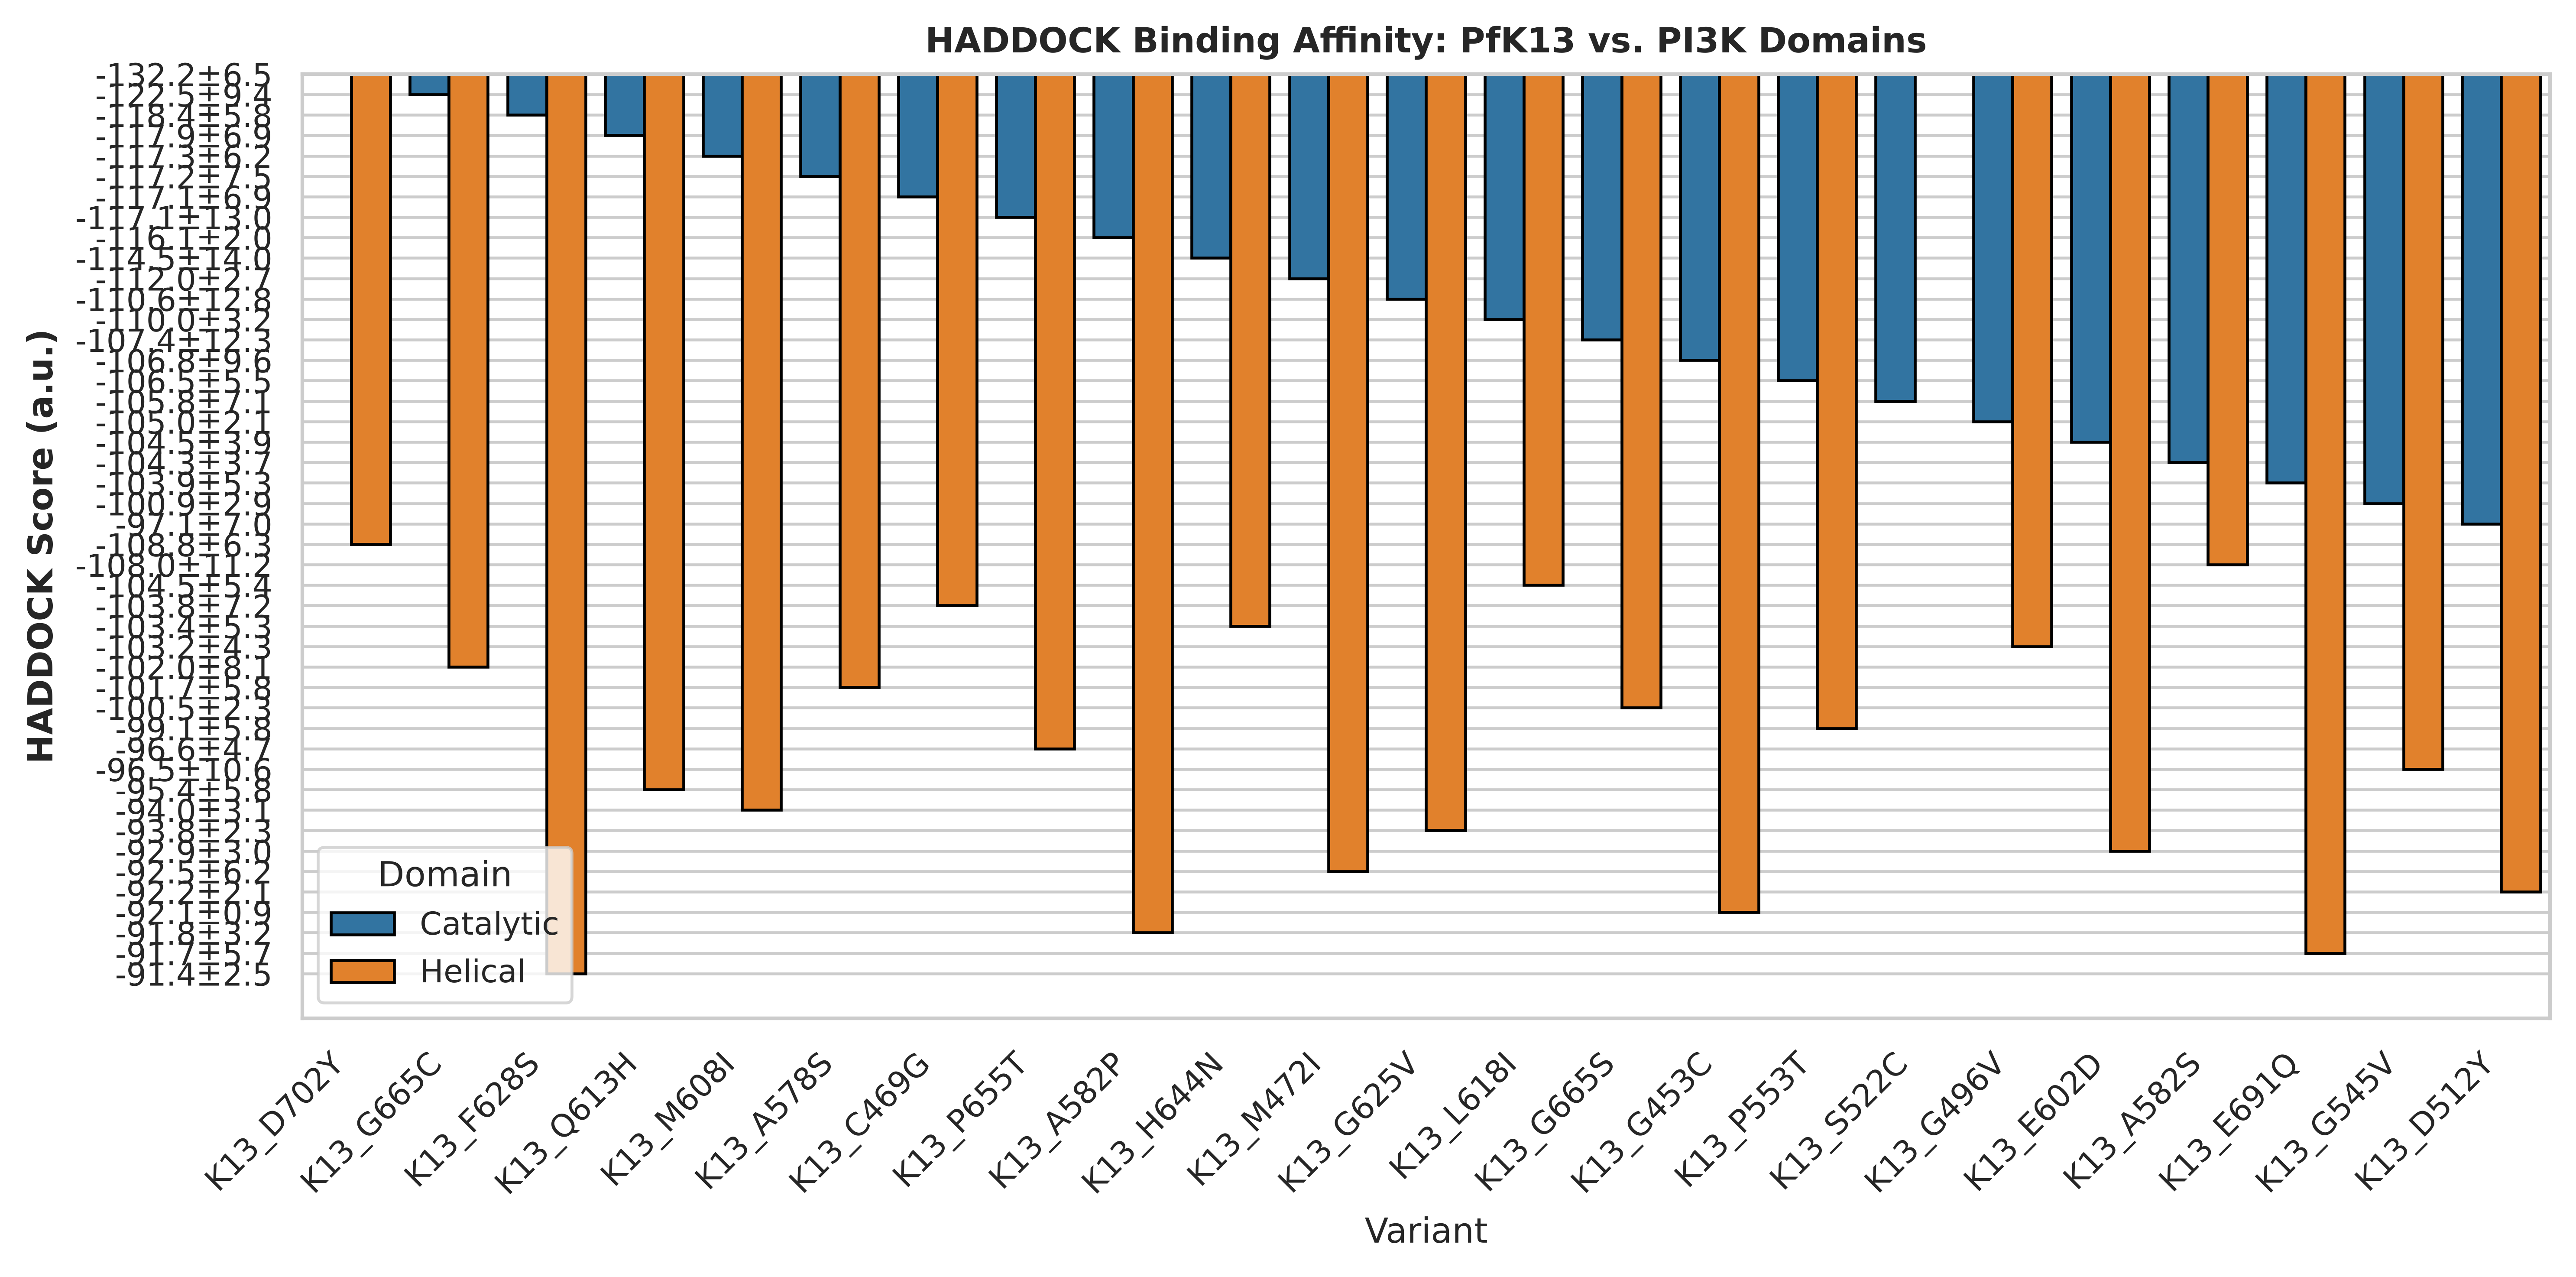

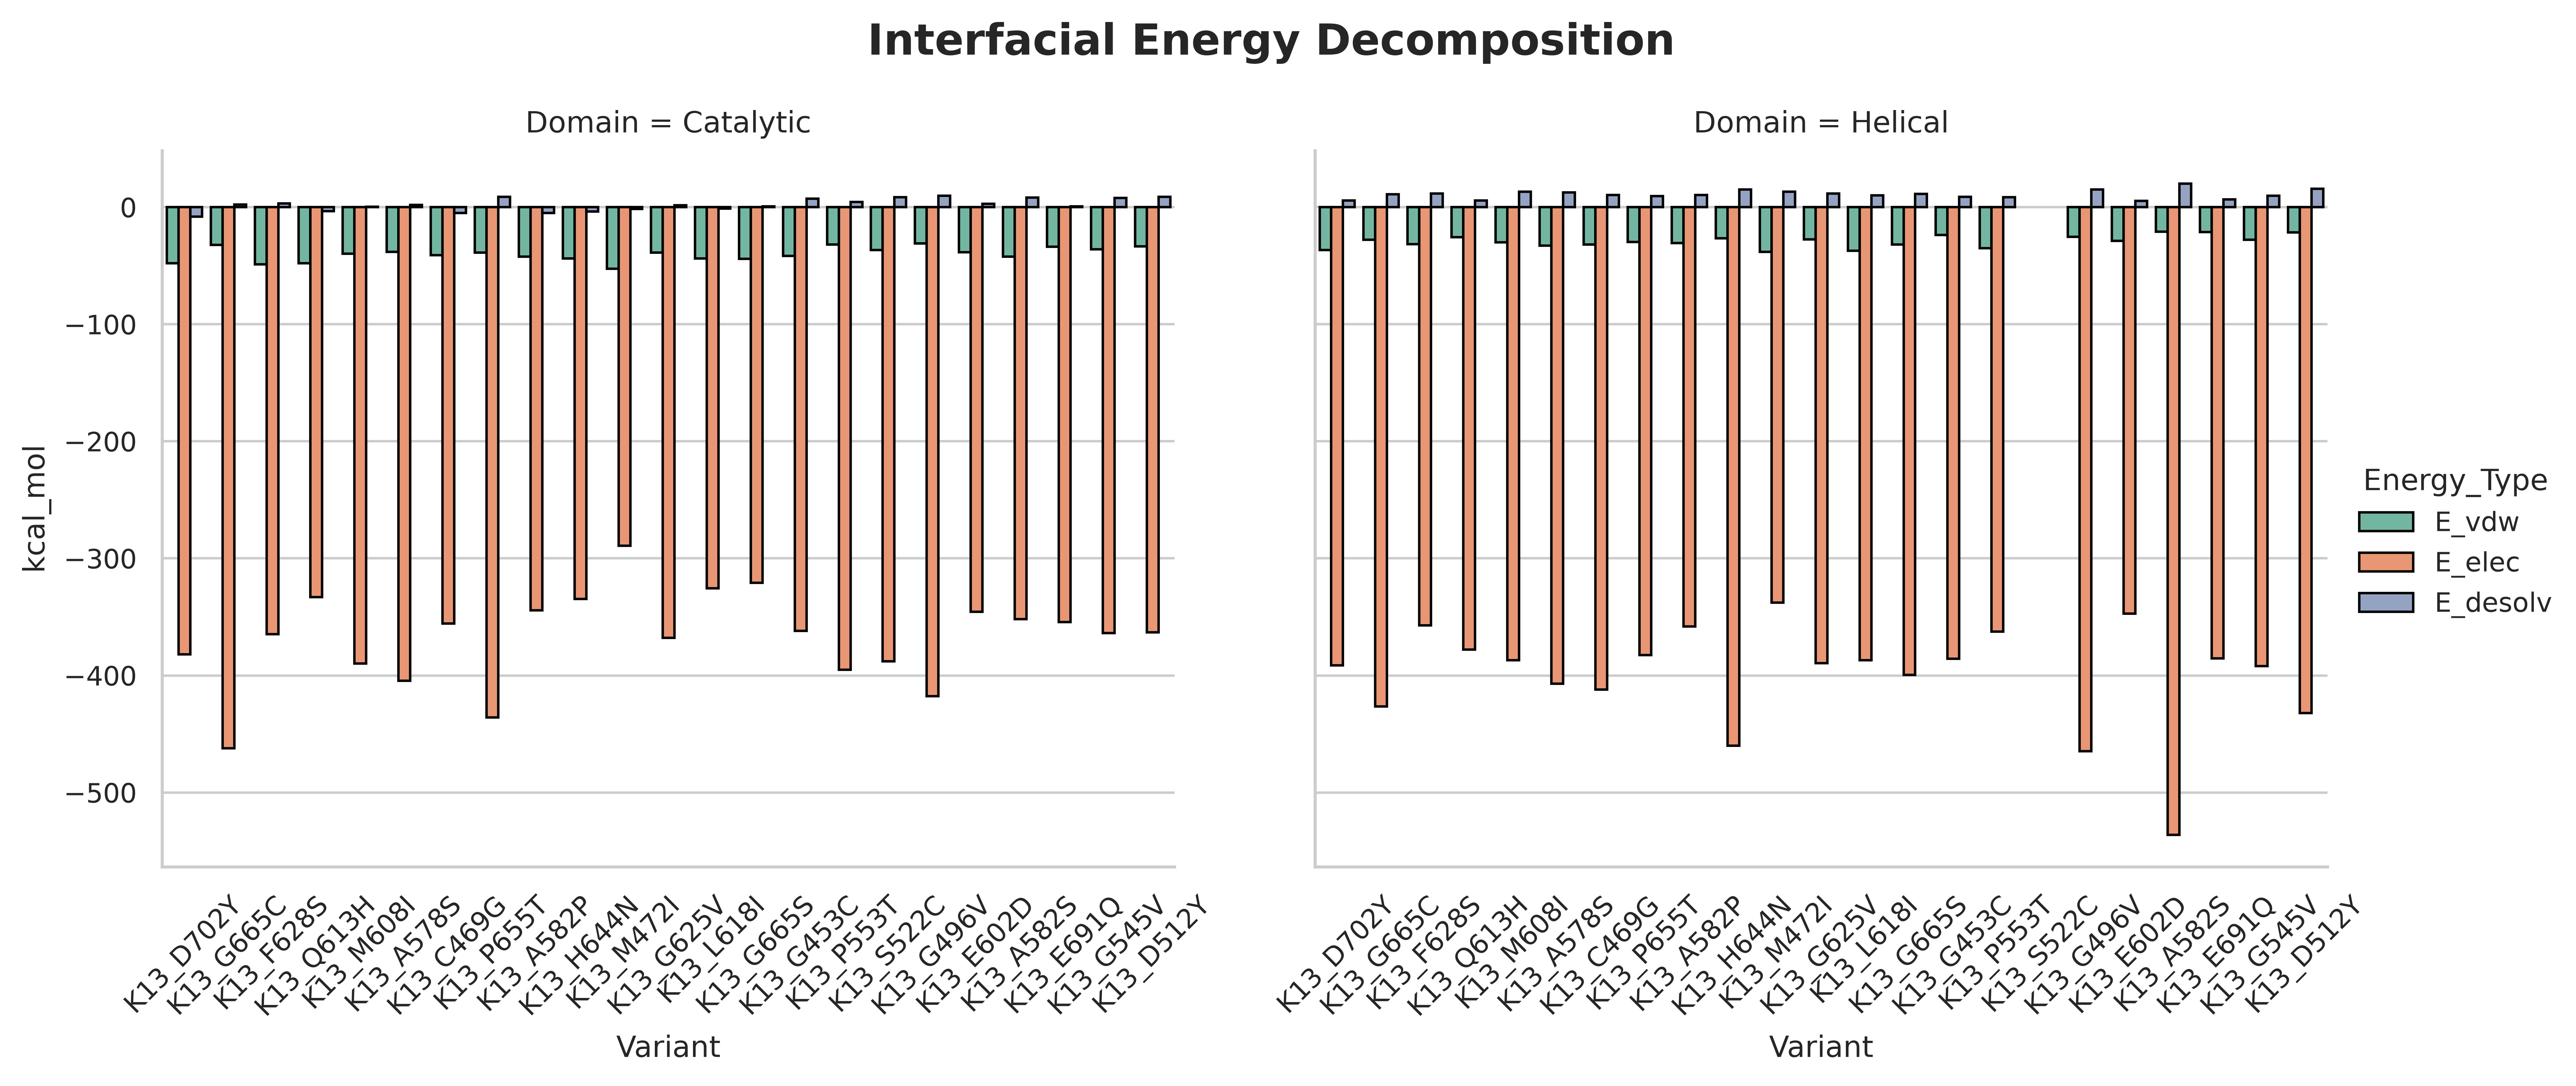

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure variables persist if running cells out of order
if 'df_haddock_mmgbsa' not in locals():
    df_haddock_mmgbsa = pd.read_csv(os.path.join(OUTPUT_DIR, "screening_summary_master.tsv"), sep="\t")

# Set publication standards
plt.rcParams.update({
    "font.size": 11,
    "font.family": "sans-serif",
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.dpi": 600,
    "savefig.dpi": 600
})
sns.set_theme(style="whitegrid", context="paper")
palette = {"Catalytic": "#1f77b4", "Helical": "#ff7f0e"}

# -------------------------------------------------------------
# Figure 1: HADDOCK Binding Affinities
# -------------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.barplot(data=df_haddock_mmgbsa, x="Variant", y="HADDOCK_Score", hue="Domain", palette=palette, edgecolor="black")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("HADDOCK Binding Affinity: PfK13 vs. PI3K Domains", weight="bold")
plt.ylabel("HADDOCK Score (a.u.)", weight="bold")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure1_HADDOCK_Scores_600dpi.png"))
plt.show()

# -------------------------------------------------------------
# Figure 2: AmberTools MM/GBSA Absolute Binding Free Energy
# -------------------------------------------------------------
if df_haddock_mmgbsa["MMGBSA_dG_kcal_mol"].notna().any():
    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_haddock_mmgbsa, x="Variant", y="MMGBSA_dG_kcal_mol", hue="Domain", palette=palette, edgecolor="black")
    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.title("MM/GBSA Absolute Binding Free Energy", weight="bold")
    plt.ylabel("ΔG Binding (kcal/mol)", weight="bold")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Figure2_MMGBSA_Energies_600dpi.png"))
    plt.show()

# -------------------------------------------------------------
# Figure 3: Interfacial Energy Decomposition
# -------------------------------------------------------------
melted = df_haddock_mmgbsa.melt(id_vars=["Variant", "Domain"], value_vars=["E_vdw", "E_elec", "E_desolv"],
                     var_name="Energy_Type", value_name="kcal_mol")
g = sns.catplot(data=melted, x="Variant", y="kcal_mol", hue="Energy_Type", col="Domain",
                kind="bar", palette="Set2", edgecolor="black", height=4.5, aspect=1.2)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Interfacial Energy Decomposition", weight="bold")
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=45)
plt.savefig(os.path.join(OUTPUT_DIR, "Figure3_Energy_Decomposition_600dpi.png"))
plt.show()

# -------------------------------------------------------------
# Figure 4: Interface Packing vs MM/GBSA Score
# -------------------------------------------------------------
if df_haddock_mmgbsa["MMGBSA_dG_kcal_mol"].notna().any():
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_haddock_mmgbsa, x="BSA_Å2", y="MMGBSA_dG_kcal_mol", hue="Domain", style="Variant", s=130, palette=palette)
    plt.title("Buried Surface Area vs. MM/GBSA Free Energy", weight="bold")
    plt.ylabel("ΔG Binding (kcal/mol)", weight="bold")
    plt.xlabel("Buried Surface Area (Å²)", weight="bold")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Figure4_BSA_vs_MMGBSA_600dpi.png"))
    plt.show()

Extracting the Best Haddock Cluster Complex

In [ ]:
import os
import glob
import shutil

BASE_DIR = "/home/adedayoadedisa/K13_MASTER_PIPELINE"
out_dir = os.path.join(BASE_DIR, "mutants/mutant_complex")
os.makedirs(out_dir, exist_ok=True)

haddock_dirs = sorted(glob.glob(os.path.join(BASE_DIR, "run_K13_*")))
print(f"Checking {len(haddock_dirs)} HADDOCK3 screening runs...\n")

extracted_count = 0

for hdir in haddock_dirs:
    var_name = os.path.basename(hdir).replace("run_", "")
    target_pdb = os.path.join(out_dir, f"{var_name}_complex.pdb")

    stage_dirs = sorted(glob.glob(os.path.join(hdir, "output/*_*")))
    if not stage_dirs:
        print(f"[-] {var_name:30s} | In progress or initializing...")
        continue

    best_pdb = None
    best_cluster_id = None
    best_score = None

    # Inspect stages in reverse order to find capri evaluation tables
    for stage in reversed(stage_dirs):
        clt_tsv = os.path.join(stage, "capri_clt.tsv")
        ss_tsv = os.path.join(stage, "capri_ss.tsv")

        if os.path.exists(clt_tsv) and os.path.exists(ss_tsv):
            try:
                # 1. Parse capri_clt.tsv for the cluster with lowest (most negative) score
                with open(clt_tsv, "r") as f:
                    clt_lines = [l.strip().split("\t") for l in f if l.strip() and not l.startswith("#")]
                
                if len(clt_lines) > 1:
                    header = clt_lines[0]
                    clusters = [dict(zip(header, r)) for r in clt_lines[1:]]
                    
                    # Ignore unclustered structures ('-')
                    valid_clusters = [c for c in clusters if c.get("cluster_id", "").strip() != "-"]
                    
                    if valid_clusters:
                        valid_clusters.sort(key=lambda x: float(x.get("score", 0.0)))
                        top_cluster = valid_clusters[0]
                        best_cluster_id = str(top_cluster.get("cluster_id", "")).strip()
                        best_score = float(top_cluster.get("score", 0.0))

                        # 2. Parse capri_ss.tsv for the best-scoring model in that cluster
                        with open(ss_tsv, "r") as f:
                            ss_lines = [l.strip().split("\t") for l in f if l.strip() and not l.startswith("#")]
                        
                        if len(ss_lines) > 1:
                            ss_header = ss_lines[0]
                            models = [dict(zip(ss_header, r)) for r in ss_lines[1:]]
                            
                            cluster_models = [
                                m for m in models 
                                if str(m.get("capri_cluster", m.get("cluster_id", ""))).strip() == best_cluster_id
                            ]
                            
                            if cluster_models:
                                cluster_models.sort(key=lambda x: float(x.get("score", 0.0)))
                                top_model_name = os.path.basename(cluster_models[0].get("model", ""))
                                candidate_path = os.path.join(stage, top_model_name)
                                if os.path.exists(candidate_path):
                                    best_pdb = candidate_path
                                    break
            except Exception:
                pass

        # Fallback for unclustered runs: pick absolute lowest-scoring model from capri_ss.tsv
        if not best_pdb and os.path.exists(ss_tsv):
            try:
                with open(ss_tsv, "r") as f:
                    ss_lines = [l.strip().split("\t") for l in f if l.strip() and not l.startswith("#")]
                if len(ss_lines) > 1:
                    ss_header = ss_lines[0]
                    models = [dict(zip(ss_header, r)) for r in ss_lines[1:]]
                    models.sort(key=lambda x: float(x.get("score", 0.0)))
                    top_model_name = os.path.basename(models[0].get("model", ""))
                    candidate_path = os.path.join(stage, top_model_name)
                    if os.path.exists(candidate_path):
                        best_pdb = candidate_path
                        best_cluster_id = "Single"
                        best_score = float(models[0].get("score", 0.0))
                        break
            except Exception:
                pass

    if best_pdb and os.path.exists(best_pdb):
        shutil.copy(best_pdb, target_pdb)
        extracted_count += 1
        print(f"[✓] {var_name:30s} | Best Cluster ID: {best_cluster_id:<5s} | HADDOCK Score: {best_score:<8.2f} -> {os.path.basename(best_pdb)}")
    else:
        print(f"[~] {var_name:30s} | Could not parse top cluster structure")

print(f"\nTotal extracted PDB complexes in mutants/mutant_complex/: {len(glob.glob(os.path.join(out_dir, '*.pdb')))}")

Inter-chain Bond Networks

In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd
import MDAnalysis as mda
from MDAnalysis.analysis.distances import distance_array

# Directories
OUTPUT_DIR = "Analysis_results"
VARIANT_TSV_DIR = os.path.join(OUTPUT_DIR, "variant_tsvs")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VARIANT_TSV_DIR, exist_ok=True)

# Search patterns for PfK13-PI3K complex PDB structures
PDB_PATTERNS = [
    "mutants/mutant_complex/*.pdb",
    "hawkdock_runs/*/*complex*.pdb"
]

AA_PROPERTIES = {
    'A': 'Aliphatic/Hydrophobic', 'V': 'Aliphatic/Hydrophobic', 'I': 'Aliphatic/Hydrophobic',
    'L': 'Aliphatic/Hydrophobic', 'M': 'Hydrophobic', 'F': 'Aromatic/Hydrophobic',
    'W': 'Aromatic/Hydrophobic', 'P': 'Conformationally Rigid', 'G': 'Conformationally Flexible',
    'S': 'Polar Uncharged', 'T': 'Polar Uncharged', 'C': 'Polar/Sulfhydryl',
    'N': 'Polar Uncharged', 'Q': 'Polar Uncharged', 'Y': 'Aromatic/Polar',
    'D': 'Negatively Charged (Acidic)', 'E': 'Negatively Charged (Acidic)',
    'K': 'Positively Charged (Basic)', 'R': 'Positively Charged (Basic)',
    'H': 'Positively Charged (Basic)'
}

HYDROPHOBIC_RES = ["ALA", "VAL", "LEU", "ILE", "MET", "PHE", "TRP", "PRO"]
CATIONIC_RES = ["ARG", "LYS", "HIS"]
ANIONIC_RES = ["ASP", "GLU"]
AROMATIC_RES = ["PHE", "TYR", "TRP", "HIS"]


def get_physicochemical_change(mut_str):
    try:
        wt_aa, mt_aa = mut_str[0], mut_str[-1]
        wt_prop = AA_PROPERTIES.get(wt_aa, "Unknown")
        mt_prop = AA_PROPERTIES.get(mt_aa, "Unknown")
        return f"{wt_prop} -> {mt_prop}"
    except Exception:
        return "N/A"


def get_pfk13_domain_blade(mut_str):
    try:
        pos = int(''.join([c for c in mut_str if c.isdigit()]))
        if pos < 350:
            return "N-terminal Domain"
        elif 350 <= pos <= 441:
            return "BTB/POZ Domain"
        elif 442 <= pos <= 474:
            return "Helical Domain"
        elif 475 <= pos <= 526:
            return "Kelch Propeller - Blade 1"
        elif 527 <= pos <= 573:
            return "Kelch Propeller - Blade 2"
        elif 574 <= pos <= 613:
            return "Kelch Propeller - Blade 3"
        elif 614 <= pos <= 665:
            return "Kelch Propeller - Blade 4"
        elif 666 <= pos <= 705:
            return "Kelch Propeller - Blade 5"
        elif pos >= 706:
            return "Kelch Propeller - Blade 6"
        else:
            return "Unknown Region"
    except Exception:
        return "N/A"


def parse_filename_metadata(filename):
    """Extracts PfK13 variant name and PI3K domain target from structure path."""
    match_var = re.search(r'([A-Z]\d+[A-Z])', filename)
    variant = match_var.group(1) if match_var else "Unknown"

    fn_lower = filename.lower()
    if "helical" in fn_lower:
        pi3k_domain = "Helical Domain"
    elif "catalytic" in fn_lower:
        pi3k_domain = "Catalytic Domain"
    else:
        pi3k_domain = "Unspecified Domain"

    return variant, pi3k_domain


def get_complex_chains(u):
    """Identifies PfK13 and PI3K chain IDs automatically."""
    unique_chains = sorted(list(set(u.atoms.chainIDs)))
    if len(unique_chains) >= 2:
        return unique_chains[0], unique_chains[1]
    return "A", "B"


# ==============================================================================
# INTERACTION CALCULATION FUNCTIONS
# ==============================================================================

def analyze_interface_hbonds(u, chain1, chain2, cutoff=3.5):
    sel1 = u.select_atoms(f"chainID {chain1} and protein and (name N* O* S*)")
    sel2 = u.select_atoms(f"chainID {chain2} and protein and (name N* O* S*)")

    if len(sel1) == 0 or len(sel2) == 0:
        return pd.DataFrame()

    dists = distance_array(sel1.positions, sel2.positions)
    records = []

    for i in range(len(sel1)):
        for j in range(len(sel2)):
            d = dists[i, j]
            if 1.5 <= d <= cutoff:
                a1, a2 = sel1[i], sel2[j]
                records.append({
                    "PfK13_Atom": f"{a1.resname}{a1.resnum}:{a1.name}",
                    "PI3K_Atom": f"{a2.resname}{a2.resnum}:{a2.name}",
                    "PfK13_Residue": f"{a1.resname}{a1.resnum}",
                    "PI3K_Residue": f"{a2.resname}{a2.resnum}",
                    "Distance_A": round(float(d), 2)
                })

    df = pd.DataFrame(records)
    return df.sort_values(by="Distance_A") if not df.empty else df


def analyze_interface_salt_bridges(u, chain1, chain2, cutoff=4.0):
    pos1 = u.select_atoms(f"chainID {chain1} and resname {' '.join(CATIONIC_RES)} and (name NZ NH1 NH2 ND1 NE2)")
    neg1 = u.select_atoms(f"chainID {chain1} and resname {' '.join(ANIONIC_RES)} and (name OE1 OE2 OD1 OD2)")

    pos2 = u.select_atoms(f"chainID {chain2} and resname {' '.join(CATIONIC_RES)} and (name NZ NH1 NH2 ND1 NE2)")
    neg2 = u.select_atoms(f"chainID {chain2} and resname {' '.join(ANIONIC_RES)} and (name OE1 OE2 OD1 OD2)")

    records = []

    if len(pos1) > 0 and len(neg2) > 0:
        dists1 = distance_array(pos1.positions, neg2.positions)
        for i in range(len(pos1)):
            for j in range(len(neg2)):
                if dists1[i, j] <= cutoff:
                    a1, a2 = pos1[i], neg2[j]
                    records.append({
                        "PfK13_Residue": f"{a1.resname}{a1.resnum}:{a1.name}",
                        "PI3K_Residue": f"{a2.resname}{a2.resnum}:{a2.name}",
                        "Type": "PfK13(+)...PI3K(-)",
                        "Distance_A": round(float(dists1[i, j]), 2)
                    })

    if len(neg1) > 0 and len(pos2) > 0:
        dists2 = distance_array(neg1.positions, pos2.positions)
        for i in range(len(neg1)):
            for j in range(len(pos2)):
                if dists2[i, j] <= cutoff:
                    a1, a2 = neg1[i], pos2[j]
                    records.append({
                        "PfK13_Residue": f"{a1.resname}{a1.resnum}:{a1.name}",
                        "PI3K_Residue": f"{a2.resname}{a2.resnum}:{a2.name}",
                        "Type": "PfK13(-)...PI3K(+)",
                        "Distance_A": round(float(dists2[i, j]), 2)
                    })

    df = pd.DataFrame(records)
    return df.sort_values(by="Distance_A") if not df.empty else df


def analyze_interface_hydrophobic(u, chain1, chain2, cutoff=4.0):
    hp1 = u.select_atoms(f"chainID {chain1} and resname {' '.join(HYDROPHOBIC_RES)} and (name CB CG* CD* CE* CZ*)")
    hp2 = u.select_atoms(f"chainID {chain2} and resname {' '.join(HYDROPHOBIC_RES)} and (name CB CG* CD* CE* CZ*)")

    if len(hp1) == 0 or len(hp2) == 0:
        return pd.DataFrame()

    dists = distance_array(hp1.positions, hp2.positions)
    records = []
    seen_pairs = set()

    for i in range(len(hp1)):
        for j in range(len(hp2)):
            d = dists[i, j]
            if 0.1 <= d <= cutoff:
                a1, a2 = hp1[i], hp2[j]
                r1 = f"{a1.resname}{a1.resnum}"
                r2 = f"{a2.resname}{a2.resnum}"
                pair_key = (r1, r2)
                if pair_key not in seen_pairs:
                    seen_pairs.add(pair_key)
                    records.append({
                        "PfK13_Residue": r1,
                        "PI3K_Residue": r2,
                        "Min_Distance_A": round(float(d), 2)
                    })

    df = pd.DataFrame(records)
    return df.sort_values(by="Min_Distance_A") if not df.empty else df


def analyze_interface_pi_stacking(u, chain1, chain2, cutoff=6.0):
    res1 = u.select_atoms(f"chainID {chain1} and resname {' '.join(AROMATIC_RES)}").residues
    res2 = u.select_atoms(f"chainID {chain2} and resname {' '.join(AROMATIC_RES)}").residues

    if len(res1) == 0 or len(res2) == 0:
        return pd.DataFrame()

    c1, names1 = [], []
    for r in res1:
        ring = r.atoms.select_atoms("name CG CD1 CD2 CE1 CE2 CE3 CZ CZ2 CZ3 CH2 ND1 NE2 SD")
        if len(ring) >= 5:
            c1.append(ring.center_of_mass())
            names1.append(f"{r.resname}{r.resnum}")

    c2, names2 = [], []
    for r in res2:
        ring = r.atoms.select_atoms("name CG CD1 CD2 CE1 CE2 CE3 CZ CZ2 CZ3 CH2 ND1 NE2 SD")
        if len(ring) >= 5:
            c2.append(ring.center_of_mass())
            names2.append(f"{r.resname}{r.resnum}")

    if not c1 or not c2:
        return pd.DataFrame()

    dists = distance_array(np.array(c1), np.array(c2))
    records = []

    for i in range(len(names1)):
        for j in range(len(names2)):
            d = dists[i, j]
            if d <= cutoff:
                records.append({
                    "PfK13_Aromatic_Residue": names1[i],
                    "PI3K_Aromatic_Residue": names2[j],
                    "Centroid_Distance_A": round(float(d), 2)
                })

    df = pd.DataFrame(records)
    return df.sort_values(by="Centroid_Distance_A") if not df.empty else df


# ==============================================================================
# PIPELINE EXECUTION
# ==============================================================================

discovered_pdbs = []
for pat in PDB_PATTERNS:
    discovered_pdbs.extend(glob.glob(pat))

discovered_pdbs = sorted(list(set(discovered_pdbs)))
print(f"[+] Found {len(discovered_pdbs)} PDB complex files across Helical and Catalytic domain runs.\n")

variant_domain_results = {}

for pdb_path in discovered_pdbs:
    filename = os.path.basename(pdb_path)
    variant_name, pi3k_domain = parse_filename_metadata(filename)

    print(f"--> Processing: {variant_name} | PI3K target: {pi3k_domain} ({filename})")

    try:
        u = mda.Universe(pdb_path)
        chain_k13, chain_pi3k = get_complex_chains(u)

        df_hb = analyze_interface_hbonds(u, chain_k13, chain_pi3k)
        df_sb = analyze_interface_salt_bridges(u, chain_k13, chain_pi3k)
        df_hp = analyze_interface_hydrophobic(u, chain_k13, chain_pi3k)
        df_pi = analyze_interface_pi_stacking(u, chain_k13, chain_pi3k)

        if variant_name not in variant_domain_results:
            variant_domain_results[variant_name] = {}

        variant_domain_results[variant_name][pi3k_domain] = {
            "hbonds": df_hb,
            "salt_bridges": df_sb,
            "hydrophobic": df_hp,
            "pi_stacking": df_pi
        }

    except Exception as e:
        print(f"  [!] Failed to process {filename}: {e}")

# Build per-variant TSVs and Master domain summary table
master_summary = []

for variant_name, domains_data in variant_domain_results.items():
    var_tsv = os.path.join(VARIANT_TSV_DIR, f"{variant_name}_PI3K_domains_interface.tsv")

    with open(var_tsv, "w") as f:
        f.write(f"# PfK13 Variant: {variant_name}\n")
        f.write(f"# PfK13 Domain/Blade Region: {get_pfk13_domain_blade(variant_name)}\n")
        f.write(f"# Physicochemical Change: {get_physicochemical_change(variant_name)}\n\n")

        for domain in ["Helical Domain", "Catalytic Domain"]:
            f.write(f"==========================================================\n")
            f.write(f"  INTERACTION PROFILE WITH PI3K {domain.upper()}\n")
            f.write(f"==========================================================\n\n")

            if domain in domains_data:
                ddata = domains_data[domain]

                f.write("--- HYDROGEN BONDS (<= 3.5 A) ---\n")
                if not ddata["hbonds"].empty:
                    ddata["hbonds"].to_csv(f, sep="\t", index=False)
                else:
                    f.write("None detected.\n")

                f.write("\n--- SALT BRIDGES (<= 4.0 A) ---\n")
                if not ddata["salt_bridges"].empty:
                    ddata["salt_bridges"].to_csv(f, sep="\t", index=False)
                else:
                    f.write("None detected.\n")

                f.write("\n--- HYDROPHOBIC CONTACTS (<= 4.0 A) ---\n")
                if not ddata["hydrophobic"].empty:
                    ddata["hydrophobic"].to_csv(f, sep="\t", index=False)
                else:
                    f.write("None detected.\n")

                f.write("\n--- AROMATIC / PI-STACKING (<= 6.0 A) ---\n")
                if not ddata["pi_stacking"].empty:
                    ddata["pi_stacking"].to_csv(f, sep="\t", index=False)
                else:
                    f.write("None detected.\n")
                f.write("\n")
            else:
                f.write(f"No complex PDB found for {domain}.\n\n")

    # Metrics for Master Summary
    hel_data = domains_data.get("Helical Domain", {})
    cat_data = domains_data.get("Catalytic Domain", {})

    hel_hb = len(hel_data.get("hbonds", []))
    hel_sb = len(hel_data.get("salt_bridges", []))
    hel_hp = len(hel_data.get("hydrophobic", []))

    cat_hb = len(cat_data.get("hbonds", []))
    cat_sb = len(cat_data.get("salt_bridges", []))
    cat_hp = len(cat_data.get("hydrophobic", []))

    master_summary.append({
        "Variant": variant_name,
        "PfK13_Domain_Propeller_Blade": get_pfk13_domain_blade(variant_name),
        "Physicochemical_Change": get_physicochemical_change(variant_name),
        "PI3K_Helical_H_Bonds": hel_hb,
        "PI3K_Helical_Salt_Bridges": hel_sb,
        "PI3K_Helical_Hydrophobic": hel_hp,
        "PI3K_Catalytic_H_Bonds": cat_hb,
        "PI3K_Catalytic_Salt_Bridges": cat_sb,
        "PI3K_Catalytic_Hydrophobic": cat_hp,
        "Preferred_PI3K_Domain_Interface": "Helical" if (hel_hb + hel_sb + hel_hp) > (cat_hb + cat_sb + cat_hp) else "Catalytic"
    })

if master_summary:
    df_master = pd.DataFrame(master_summary)
    master_path = os.path.join(OUTPUT_DIR, "PfK13_PI3K_Domain_Specific_Interactions.tsv")
    df_master.to_csv(master_path, sep="\t", index=False)
    print(f"\n[✓] Individual per-variant domain files saved to: {VARIANT_TSV_DIR}/")
    print(f"[✓] Master PI3K Domain Summary Table saved to: {master_path}")
    display(df_master)
else:
    print("[!] No complex PDBs processed successfully.")

PyMOL 3D Interface Rendering and Bond **Extraction**

NEWLY UPDATED MMGBSA


MAIN MMBGSA

In [27]:
import glob
import os
import subprocess
import pandas as pd
from IPython.display import display

# ==============================================================================
# CONFIGURATION & GLOBAL PATHS
# ==============================================================================
BASE_DIR = "/home/adedayoadedisa/K13_MASTER_PIPELINE"
CONDA_BIN = "/home/adedayoadedisa/miniconda3/bin"

env = os.environ.copy()
env["PATH"] = f"{CONDA_BIN}:{env.get('PATH', '')}"

complex_dir = os.path.join(BASE_DIR, "mutants/mutant_complex")

# Create MDP directory and write MMPBSA parameter file
mdp_dir = os.path.join(BASE_DIR, "mdp_files")
os.makedirs(mdp_dir, exist_ok=True)
mdp_file = os.path.join(mdp_dir, "mmpbsa_hawkdock.in")

with open(mdp_file, "w") as f:
  f.write("""&general
  startframe = 1,
  endframe = 1,
  verbose = 2,
/
&gb
  igb = 2,
  saltcon = 0.150,
  surften = 0.0072,
/
&decomp
  idecomp = 1,
  dec_verbose = 1,
/
""")

VALID_AMINO_ACIDS = {
    "ALA",
    "ARG",
    "ASN",
    "ASP",
    "CYS",
    "GLN",
    "GLU",
    "GLY",
    "HIS",
    "HID",
    "HIE",
    "HIP",
    "ILE",
    "LEU",
    "LYS",
    "MET",
    "PHE",
    "PRO",
    "SER",
    "THR",
    "TRP",
    "TYR",
    "VAL",
}


# ==============================================================================
# HELPER FUNCTIONS: PDB CLEANING & CHAIN SEPARATION
# ==============================================================================
def is_hydrogen(line):
  """Detects hydrogen atoms across standard and non-standard naming conventions."""
  element = line[76:78].strip().upper() if len(line) >= 78 else ""
  if element == "H":
    return True
  atom_name = line[12:16].strip().upper()
  if atom_name.startswith("H"):
    return True
  if (
      len(atom_name) > 1
      and atom_name[0].isdigit()
      and atom_name[1:].startswith("H")
  ):
    return True
  return False


def normalize_line(line):
  """Normalizes terminal residue codes (e.g., CPHE -> PHE)."""
  raw_res = line[16:21].strip()
  if raw_res in VALID_AMINO_ACIDS:
    return line
  if len(raw_res) == 4 and raw_res[0] in ["C", "N"]:
    sub_res = raw_res[1:]
    if sub_res in VALID_AMINO_ACIDS:
      new_res = f"{sub_res:>3} "
      return line[:17] + new_res + line[21:]
  return line


def process_complex_pdb(pdb_path):
  """Cleans heavy atoms, normalizes residue names, and splits into Receptor and Ligand."""
  rec_lines, lig_lines = [], []
  current_chain = 1
  prev_resnum = None
  prev_segid = None
  prev_chain_id = None

  with open(pdb_path, "r") as f:
    for line in f:
      if line.startswith("TER"):
        if rec_lines and current_chain == 1:
          current_chain = 2
        continue

      if not line.startswith("ATOM"):
        continue

      if is_hydrogen(line):
        continue

      cleaned_line = normalize_line(line)
      chain_id = cleaned_line[21].strip()
      segid = cleaned_line[72:76].strip()
      try:
        resnum = int(cleaned_line[22:26].strip())
      except ValueError:
        resnum = None

      if current_chain == 1 and len(rec_lines) > 0:
        if prev_chain_id and chain_id and chain_id != prev_chain_id:
          current_chain = 2
        elif prev_segid and segid and segid != prev_segid:
          current_chain = 2
        elif (
            prev_resnum is not None
            and resnum is not None
            and resnum < (prev_resnum - 50)
        ):
          current_chain = 2

      if resnum is not None:
        prev_resnum = resnum
      if segid:
        prev_segid = segid
      if chain_id:
        prev_chain_id = chain_id

      if current_chain == 1:
        rec_lines.append(cleaned_line)
      else:
        lig_lines.append(cleaned_line)

  return rec_lines, lig_lines


# ==============================================================================
# PHASE 1: EXECUTE MM/GBSA ON EXISTING COMPLEXES
# ==============================================================================
print("==================================================")
print("PHASE 1: Executing MM/GBSA Calculations")
print("==================================================")

pdb_files = sorted(glob.glob(os.path.join(complex_dir, "*.pdb")))

if not pdb_files:
  print(f"[!] No .pdb files found in {complex_dir}")
else:
  print(
      f"[✓] Found {len(pdb_files)} existing complex files. Processing"
      " directly...\n"
  )

for pdb_path in pdb_files:
  variant_name = (
      os.path.basename(pdb_path).replace(".pdb", "").replace("_complex", "")
  )
  work_dir = os.path.join(BASE_DIR, "hawkdock_runs", variant_name)
  os.makedirs(work_dir, exist_ok=True)

  dat_out = os.path.join(work_dir, "HAWKDOCK_MMGBSA_RESULTS.dat")

  print(f"Processing model: {os.path.basename(pdb_path)} ...")

  rec_lines, lig_lines = process_complex_pdb(pdb_path)

  if not rec_lines or not lig_lines:
    print(
        f"[!] ERROR: Separation failed for {variant_name} (Rec:"
        f" {len(rec_lines)}, Lig: {len(lig_lines)})"
    )
    continue

  clean_pdb = os.path.join(work_dir, "clean_complex.pdb")
  rec_pdb = os.path.join(work_dir, "rec.pdb")
  lig_pdb = os.path.join(work_dir, "lig.pdb")

  with open(clean_pdb, "w") as f:
    f.writelines(rec_lines)
    f.write("TER\n")
    f.writelines(lig_lines)
    f.write("TER\nEND\n")

  with open(rec_pdb, "w") as f:
    f.writelines(rec_lines)
    f.write("TER\nEND\n")

  with open(lig_pdb, "w") as f:
    f.writelines(lig_lines)
    f.write("TER\nEND\n")

  tleap_in = os.path.join(work_dir, "tleap.in")
  with open(tleap_in, "w") as f:
    f.write("""source leaprc.protein.ff14SB
source leaprc.water.tip3p
set default PBradii mbondi2

complex = loadpdb clean_complex.pdb
receptor = loadpdb rec.pdb
ligand = loadpdb lig.pdb

saveamberparm complex complex.prmtop complex.inpcrd
saveamberparm receptor receptor.prmtop receptor.inpcrd
saveamberparm ligand ligand.prmtop ligand.inpcrd
quit
""")

  subprocess.run(
      f"{CONDA_BIN}/tleap -f tleap.in > tleap.log 2>&1",
      shell=True,
      cwd=work_dir,
      env=env,
  )

  if not os.path.exists(os.path.join(work_dir, "complex.prmtop")):
    print(
        f"[!] ERROR: tleap failed for {variant_name}. Check {work_dir}/tleap.log"
    )
    continue

  mmpbsa_cmd = (
      f"{CONDA_BIN}/MMPBSA.py -O -i {mdp_file} -cp complex.prmtop -rp"
      " receptor.prmtop -lp ligand.prmtop -y complex.inpcrd -o"
      " HAWKDOCK_MMGBSA_RESULTS.dat -eo HAWKDOCK_MMGBSA_RESULTS.csv >"
      " mmgbsa_hawkdock.log 2>&1"
  )
  subprocess.run(mmpbsa_cmd, shell=True, cwd=work_dir, env=env)

  if os.path.exists(dat_out) and os.path.getsize(dat_out) > 0:
    print(f"[✓] Finished MM/GBSA: {variant_name}")
  else:
    print(
        f"[!] MMGBSA failed for {variant_name}. Check"
        f" {work_dir}/mmgbsa_hawkdock.log"
    )

# ==============================================================================
# PHASE 2: PARSE & DIRECTLY CALCULATE MM/GBSA BINDING ENERGIES
# ==============================================================================
print("\n==================================================")
print("PHASE 2: Parsing & Computing MM/GBSA Energy Components")
print("==================================================")

mmgbsa_records = []

for pdb_path in pdb_files:
  variant_name = (
      os.path.basename(pdb_path).replace(".pdb", "").replace("_complex", "")
  )
  dat_out = os.path.join(
      BASE_DIR, "hawkdock_runs", variant_name, "HAWKDOCK_MMGBSA_RESULTS.dat"
  )

  row = {
      "Variant": variant_name,
      "VDWAALS_kcal_mol": None,
      "EEL_kcal_mol": None,
      "EGB_kcal_mol": None,
      "ESURF_kcal_mol": None,
      "G_gas_kcal_mol": None,
      "G_solv_kcal_mol": None,
      "MMGBSA_dG_kcal_mol": None,
  }

  if os.path.exists(dat_out) and os.path.getsize(dat_out) > 0:
    with open(dat_out, "r") as f:
      in_diff = False
      for line in f:
        if "Differences (Complex - Receptor - Ligand)" in line:
          in_diff = True
          continue
        if in_diff:
          parts = line.strip().split()
          if not parts:
            continue
          if parts[0] == "VDWAALS":
            row["VDWAALS_kcal_mol"] = float(parts[1])
          elif parts[0] == "EEL":
            row["EEL_kcal_mol"] = float(parts[1])
          elif parts[0] == "EGB":
            row["EGB_kcal_mol"] = float(parts[1])
          elif parts[0] == "ESURF":
            row["ESURF_kcal_mol"] = float(parts[1])
          elif len(parts) >= 3 and parts[0] == "G" and parts[1] == "gas":
            row["G_gas_kcal_mol"] = float(parts[2])
          elif len(parts) >= 3 and parts[0] == "G" and parts[1] == "solv":
            row["G_solv_kcal_mol"] = float(parts[2])
          elif parts[0] == "TOTAL":
            row["MMGBSA_dG_kcal_mol"] = float(parts[1])

    # Direct calculation fallback if G_gas, G_solv, or TOTAL are None
    if (
        row["VDWAALS_kcal_mol"] is not None
        and row["EEL_kcal_mol"] is not None
        and row["EGB_kcal_mol"] is not None
        and row["ESURF_kcal_mol"] is not None
    ):
      if row["G_gas_kcal_mol"] is None:
        row["G_gas_kcal_mol"] = round(
            row["VDWAALS_kcal_mol"] + row["EEL_kcal_mol"], 4
        )

      if row["G_solv_kcal_mol"] is None:
        row["G_solv_kcal_mol"] = round(
            row["EGB_kcal_mol"] + row["ESURF_kcal_mol"], 4
        )

      if row["MMGBSA_dG_kcal_mol"] is None:
        row["MMGBSA_dG_kcal_mol"] = round(
            row["G_gas_kcal_mol"] + row["G_solv_kcal_mol"], 4
        )

  mmgbsa_records.append(row)

df_mmgbsa = pd.DataFrame(mmgbsa_records)

if not df_mmgbsa.empty and "MMGBSA_dG_kcal_mol" in df_mmgbsa.columns:
  df_mmgbsa = df_mmgbsa.sort_values(
      by="MMGBSA_dG_kcal_mol", ascending=True, na_position="last"
  )

summary_file = os.path.join(BASE_DIR, "mmgbsa_energy_components_summary.tsv")
df_mmgbsa.to_csv(summary_file, sep="\t", index=False)

print(f"[✓] Full energy breakdown saved to: {summary_file}\n")
display(df_mmgbsa)

PHASE 1: Executing MM/GBSA Calculations
[✓] Found 30 existing complex files. Processing directly...

Processing model: K13_A578S_catalytic_complex.pdb ...
[✓] Finished MM/GBSA: K13_A578S_catalytic
Processing model: K13_A578S_helical_complex.pdb ...
[✓] Finished MM/GBSA: K13_A578S_helical
Processing model: K13_A582P_catalytic_complex.pdb ...
[✓] Finished MM/GBSA: K13_A582P_catalytic
Processing model: K13_A582P_helical_complex.pdb ...
[✓] Finished MM/GBSA: K13_A582P_helical
Processing model: K13_A582S_catalytic_complex.pdb ...
[✓] Finished MM/GBSA: K13_A582S_catalytic
Processing model: K13_A582S_helical_complex.pdb ...
[✓] Finished MM/GBSA: K13_A582S_helical
Processing model: K13_C469G_catalytic_complex.pdb ...
[✓] Finished MM/GBSA: K13_C469G_catalytic
Processing model: K13_C469G_helical_complex.pdb ...
[✓] Finished MM/GBSA: K13_C469G_helical
Processing model: K13_D512Y_catalytic_complex.pdb ...
[✓] Finished MM/GBSA: K13_D512Y_catalytic
Processing model: K13_D512Y_helical_complex.pdb ...

,Variant,VDWAALS_kcal_mol,EEL_kcal_mol,EGB_kcal_mol,ESURF_kcal_mol,G_gas_kcal_mol,G_solv_kcal_mol,MMGBSA_dG_kcal_mol
22,K13_G545V_catalytic,-42.0950,-469.9991,524.7666,-11.6419,-512.0941,513.1247,1.0306
13,K13_E602D_helical,-54.5542,-908.9505,977.3227,-11.1471,-963.5047,966.1756,2.6709
25,K13_G625V_helical,-15.7185,-1326.0006,1355.9076,-8.1849,-1341.7191,1347.7227,6.0036
29,K13_S522C_catalytic,-11.6952,55.6020,-36.0871,-1.0492,43.9068,-37.1363,6.7705
1,K13_A578S_helical,-61.6886,-1015.0643,1105.3372,-11.1878,-1076.7529,1094.1494,17.3965
23,K13_G545V_helical,-63.6847,-1187.7814,1288.7013,-11.4441,-1251.4661,1277.2572,25.7911
18,K13_G453C_catalytic,-44.8687,-394.5838,479.3179,-12.5062,-439.4525,466.8117,27.3592
0,K13_A578S_catalytic,-48.9778,-829.2878,920.3306,-12.8271,-878.2656,907.5035,29.2379
28,K13_G665S_helical,-43.3451,-448.2160,528.2397,-6.2970,-491.5611,521.9427,30.3816
6,K13_C469G_catalytic,-57.7883,272.1741,-169.7309,-13.8418,214.3858,-183.5727,30.8131


In [ ]:
import glob
import os
import subprocess
import pandas as pd
from IPython.display import display

# ==============================================================================
# CONFIGURATION & GLOBAL PATHS
# ==============================================================================
BASE_DIR = "/home/adedayoadedisa/K13_MASTER_PIPELINE"
CONDA_BIN = "/home/adedayoadedisa/miniconda3/bin"

env = os.environ.copy()
env["PATH"] = f"{CONDA_BIN}:{env.get('PATH', '')}"

complex_dir = os.path.join(BASE_DIR, "mutants/mutant_complex")

# Create MDP directory and write MMPBSA parameter file
mdp_dir = os.path.join(BASE_DIR, "mdp_files")
os.makedirs(mdp_dir, exist_ok=True)
mdp_file = os.path.join(mdp_dir, "mmpbsa_hawkdock.in")

with open(mdp_file, "w") as f:
    f.write("""&general
  startframe = 1,
  endframe = 1,
  verbose = 2,
/
&gb
  igb = 2,
  saltcon = 0.150,
  surften = 0.0072,
/
&decomp
  idecomp = 1,
  dec_verbose = 1,
/
""")

# Create 5000-step sander minimization input file (HawkDock protocol)
min_file = os.path.join(mdp_dir, "min_hawkdock.in")
with open(min_file, "w") as f:
    f.write("""5000 steps HawkDock-style minimization in implicit solvent
 &cntrl
  imin=1, maxcyc=5000, ncyc=2000,
  cut=999.0, igb=2, ntb=0,
  ntpr=500
 /
""")

VALID_AMINO_ACIDS = {
    "ALA", "ARG", "ASN", "ASP", "CYS", "GLN", "GLU", "GLY", "HIS", "HID", "HIE", "HIP",
    "ILE", "LEU", "LYS", "MET", "PHE", "PRO", "SER", "THR", "TRP", "TYR", "VAL"
}

def is_hydrogen(line):
    element = line[76:78].strip().upper() if len(line) >= 78 else ""
    if element == "H": return True
    atom_name = line[12:16].strip().upper()
    if atom_name.startswith("H"): return True
    if len(atom_name) > 1 and atom_name[0].isdigit() and atom_name[1:].startswith("H"): return True
    return False

def normalize_line(line):
    raw_res = line[16:21].strip()
    if raw_res in VALID_AMINO_ACIDS: return line
    if len(raw_res) == 4 and raw_res[0] in ["C", "N"]:
        sub_res = raw_res[1:]
        if sub_res in VALID_AMINO_ACIDS:
            new_res = f"{sub_res:>3} "
            return line[:17] + new_res + line[21:]
    return line

def process_complex_pdb(pdb_path):
    rec_lines, lig_lines = [], []
    current_chain = 1
    prev_resnum = None
    prev_segid = None
    prev_chain_id = None

    with open(pdb_path, "r") as f:
        for line in f:
            if line.startswith("TER"):
                if rec_lines and current_chain == 1:
                    current_chain = 2
                continue

            if not line.startswith("ATOM"):
                continue

            if is_hydrogen(line):
                continue

            cleaned_line = normalize_line(line)
            chain_id = cleaned_line[21].strip()
            segid = cleaned_line[72:76].strip()
            try:
                resnum = int(cleaned_line[22:26].strip())
            except ValueError:
                resnum = None

            if current_chain == 1 and len(rec_lines) > 0:
                if prev_chain_id and chain_id and chain_id != prev_chain_id:
                    current_chain = 2
                elif prev_segid and segid and segid != prev_segid:
                    current_chain = 2
                elif prev_resnum is not None and resnum is not None and resnum < (prev_resnum - 50):
                    current_chain = 2

            if resnum is not None: prev_resnum = resnum
            if segid: prev_segid = segid
            if chain_id: prev_chain_id = chain_id

            if current_chain == 1:
                rec_lines.append(cleaned_line)
            else:
                lig_lines.append(cleaned_line)

    return rec_lines, lig_lines

# ==============================================================================
# PHASE 1: EXECUTE MINIMIZATION & MM/GBSA ON 3 TEST COMPLEXES
# ==============================================================================
print("==================================================")
print("PHASE 1: Minimization & MM/GBSA Calculations (TEST: 3 COMPLEX FILES)")
print("==================================================")

# Sliced to process only the first 3 complex files
pdb_files = sorted(glob.glob(os.path.join(complex_dir, "*.pdb")))[:3]

if not pdb_files:
    print(f"[!] No .pdb files found in {complex_dir}")
else:
    print(f"[✓] Processing {len(pdb_files)} test complex files directly...\n")

for pdb_path in pdb_files:
    variant_name = os.path.basename(pdb_path).replace(".pdb", "").replace("_complex", "")
    work_dir = os.path.join(BASE_DIR, "hawkdock_runs", variant_name)
    os.makedirs(work_dir, exist_ok=True)

    dat_out = os.path.join(work_dir, "HAWKDOCK_MMGBSA_RESULTS.dat")

    print(f"Processing model: {os.path.basename(pdb_path)} ...")

    rec_lines, lig_lines = process_complex_pdb(pdb_path)

    if not rec_lines or not lig_lines:
        print(f"[!] ERROR: Separation failed for {variant_name}")
        continue

    clean_pdb = os.path.join(work_dir, "clean_complex.pdb")
    rec_pdb = os.path.join(work_dir, "rec.pdb")
    lig_pdb = os.path.join(work_dir, "lig.pdb")

    with open(clean_pdb, "w") as f:
        f.writelines(rec_lines); f.write("TER\n"); f.writelines(lig_lines); f.write("TER\nEND\n")
    with open(rec_pdb, "w") as f:
        f.writelines(rec_lines); f.write("TER\nEND\n")
    with open(lig_pdb, "w") as f:
        f.writelines(lig_lines); f.write("TER\nEND\n")

    # Step A: Build Amber Topologies
    tleap_in = os.path.join(work_dir, "tleap.in")
    with open(tleap_in, "w") as f:
        f.write("""source leaprc.protein.ff14SB
source leaprc.water.tip3p
set default PBradii mbondi2

complex = loadpdb clean_complex.pdb
receptor = loadpdb rec.pdb
ligand = loadpdb lig.pdb

saveamberparm complex complex.prmtop complex.inpcrd
saveamberparm receptor receptor.prmtop receptor.inpcrd
saveamberparm ligand ligand.prmtop ligand.inpcrd
quit
""")

    subprocess.run(f"{CONDA_BIN}/tleap -f tleap.in > tleap.log 2>&1", shell=True, cwd=work_dir, env=env)

    prmtop_path = os.path.join(work_dir, "complex.prmtop")
    if not os.path.exists(prmtop_path):
        print(f"[!] ERROR: tleap failed for {variant_name}. Check {work_dir}/tleap.log")
        continue

    # Step B: Run 5000-Step Sander Minimization (HawkDock Protocol)
    min_cmd = (
        f"{CONDA_BIN}/sander -O -i {min_file} -p complex.prmtop "
        f"-c complex.inpcrd -r complex_min.inpcrd > min.log 2>&1"
    )
    subprocess.run(min_cmd, shell=True, cwd=work_dir, env=env)

    min_inpcrd = os.path.join(work_dir, "complex_min.inpcrd")
    eval_inpcrd = min_inpcrd if os.path.exists(min_inpcrd) else "complex.inpcrd"

    # Step C: Execute MMPBSA.py on Minimized Coordinates
    mmpbsa_cmd = (
        f"{CONDA_BIN}/MMPBSA.py -O -i {mdp_file} "
        f"-cp complex.prmtop -rp receptor.prmtop -lp ligand.prmtop "
        f"-y {eval_inpcrd} -o HAWKDOCK_MMGBSA_RESULTS.dat "
        f"-eo HAWKDOCK_MMGBSA_RESULTS.csv > mmgbsa_hawkdock.log 2>&1"
    )
    subprocess.run(mmpbsa_cmd, shell=True, cwd=work_dir, env=env)

    if os.path.exists(dat_out) and os.path.getsize(dat_out) > 0:
        print(f"[✓] Finished MM/GBSA (Minimized): {variant_name}")
    else:
        print(f"[!] MMGBSA failed for {variant_name}. Check {work_dir}/mmgbsa_hawkdock.log")

# ==============================================================================
# PHASE 2: PARSE DETAILED ENERGY BREAKDOWN & VISUALIZE
# ==============================================================================
print("\n==================================================")
print("PHASE 2: Parsing Energy Components")
print("==================================================")

mmgbsa_records = []

for pdb_path in pdb_files:
    variant_name = os.path.basename(pdb_path).replace(".pdb", "").replace("_complex", "")
    dat_out = os.path.join(BASE_DIR, "hawkdock_runs", variant_name, "HAWKDOCK_MMGBSA_RESULTS.dat")

    row = {
        "Variant": variant_name,
        "VDWAALS_kcal_mol": None,
        "EEL_kcal_mol": None,
        "EGB_kcal_mol": None,
        "ESURF_kcal_mol": None,
        "G_gas_kcal_mol": None,
        "G_solv_kcal_mol": None,
        "MMGBSA_dG_kcal_mol": None
    }

    if os.path.exists(dat_out) and os.path.getsize(dat_out) > 0:
        with open(dat_out, "r") as f:
            in_diff = False
            for line in f:
                if "Differences (Complex - Receptor - Ligand)" in line:
                    in_diff = True
                    continue
                if in_diff:
                    parts = line.strip().split()
                    if not parts: continue
                    if parts[0] == "VDWAALS": row["VDWAALS_kcal_mol"] = float(parts[1])
                    elif parts[0] == "EEL": row["EEL_kcal_mol"] = float(parts[1])
                    elif parts[0] == "EGB": row["EGB_kcal_mol"] = float(parts[1])
                    elif parts[0] == "ESURF": row["ESURF_kcal_mol"] = float(parts[1])
                    elif len(parts) >= 3 and parts[0] == "G" and parts[1] == "gas": row["G_gas_kcal_mol"] = float(parts[2])
                    elif len(parts) >= 3 and parts[0] == "G" and parts[1] == "solv": row["G_solv_kcal_mol"] = float(parts[2])
                    elif parts[0] == "TOTAL": row["MMGBSA_dG_kcal_mol"] = float(parts[1])

        if row["VDWAALS_kcal_mol"] is not None and row["EEL_kcal_mol"] is not None and row["EGB_kcal_mol"] is not None and row["ESURF_kcal_mol"] is not None:
            if row["G_gas_kcal_mol"] is None:
                row["G_gas_kcal_mol"] = round(row["VDWAALS_kcal_mol"] + row["EEL_kcal_mol"], 4)
            if row["G_solv_kcal_mol"] is None:
                row["G_solv_kcal_mol"] = round(row["EGB_kcal_mol"] + row["ESURF_kcal_mol"], 4)
            if row["MMGBSA_dG_kcal_mol"] is None:
                row["MMGBSA_dG_kcal_mol"] = round(row["G_gas_kcal_mol"] + row["G_solv_kcal_mol"], 4)

    mmgbsa_records.append(row)

df_mmgbsa = pd.DataFrame(mmgbsa_records)

if not df_mmgbsa.empty and "MMGBSA_dG_kcal_mol" in df_mmgbsa.columns:
    df_mmgbsa = df_mmgbsa.sort_values(by="MMGBSA_dG_kcal_mol", ascending=True, na_position="last")

summary_file = os.path.join(BASE_DIR, "mmgbsa_energy_components_summary_test.tsv")
df_mmgbsa.to_csv(summary_file, sep="\t", index=False)

print(f"[✓] Test energy breakdown saved to: {summary_file}\n")
display(df_mmgbsa)

**Cross-Tabulated Table Generation**

In [28]:
import glob
import os
import re

import pandas as pd
from IPython.display import display
from pymol import cmd

# ==============================================================================
# PATHS & CONFIGURATION
# ==============================================================================
BASE_DIR = "/home/adedayoadedisa/K13_MASTER_PIPELINE"
OUTPUT_DIR = os.path.join(BASE_DIR, "Analysis_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUT_TSV = os.path.join(OUTPUT_DIR, "Publication_CrossTab_Master.tsv")
COMPLEX_DIR = os.path.join(BASE_DIR, "mutants/mutant_complex")
HAWKDOCK_DIR = os.path.join(BASE_DIR, "hawkdock_runs")


# ==============================================================================
# HELPER FUNCTIONS
# ==============================================================================
def get_top_haddock_score(run_dir):
  """Parses HADDOCK evaluation TSV files and returns the score of the top-scoring cluster (lowest energy)."""
  stage_dirs = sorted(glob.glob(os.path.join(run_dir, "output/*_*")))
  for stage in reversed(stage_dirs):
    clt_tsv = os.path.join(stage, "capri_clt.tsv")
    if os.path.isfile(clt_tsv):
      try:
        with open(clt_tsv, "r") as f:
          lines = [
              l.strip().split("\t")
              for l in f
              if l.strip() and not l.startswith("#")
          ]

        if len(lines) > 1:
          header = lines[0]
          clusters = [dict(zip(header, r)) for r in lines[1:]]
          valid_clusters = [
              c for c in clusters if c.get("cluster_id", "").strip() != "-"
          ]

          if valid_clusters:
            # Sort by HADDOCK score ascending (lowest/best energy)
            valid_clusters.sort(key=lambda x: float(x.get("score", 0.0)))
            return round(float(valid_clusters[0].get("score", 0.0)), 2)
      except Exception:
        pass

    # Fallback to capri_ss.tsv if no cluster report exists
    ss_tsv = os.path.join(stage, "capri_ss.tsv")
    if os.path.isfile(ss_tsv):
      try:
        with open(ss_tsv, "r") as f:
          lines = [
              l.strip().split("\t")
              for l in f
              if l.strip() and not l.startswith("#")
          ]
        if len(lines) > 1:
          header = lines[0]
          models = [dict(zip(header, r)) for r in lines[1:]]
          models.sort(key=lambda x: float(x.get("score", 0.0)))
          return round(float(models[0].get("score", 0.0)), 2)
      except Exception:
        pass

  return "N/A"


def get_hawkdock_mmgbsa(variant_key):
  """Extracts TOTAL binding free energy from HawkDock MM/GBSA output (.dat)."""
  possible_paths = [
      os.path.join(HAWKDOCK_DIR, variant_key, "HAWKDOCK_MMGBSA_RESULTS.dat"),
      os.path.join(
          HAWKDOCK_DIR,
          variant_key.replace("K13_", ""),
          "HAWKDOCK_MMGBSA_RESULTS.dat",
      ),
  ]

  for dat_path in possible_paths:
    if os.path.isfile(dat_path) and os.path.getsize(dat_path) > 0:
      try:
        with open(dat_path, "r") as f:
          in_diff = False
          for line in f:
            if "Differences (Complex - Receptor - Ligand)" in line:
              in_diff = True
              continue
            if in_diff and line.strip().startswith("TOTAL"):
              parts = line.strip().split()
              return round(float(parts[1]), 2)
      except Exception:
        pass

  return "N/A"


def count_interchain_hbonds(pdb_path):
  """Loads the complex PDB in PyMOL and calculates inter-chain hydrogen bonds (cutoff <= 3.5 Å)."""
  if not os.path.isfile(pdb_path):
    return "N/A"

  try:
    cmd.reinitialize()
    cmd.load(pdb_path, "complex")
    chains = cmd.get_chains("complex")

    if len(chains) >= 2:
      sel_chain1 = f"chain {chains[0]} and (elem N,O)"
      sel_chain2 = f"chain {chains[1]} and (elem N,O)"
      cmd.distance(
          "hbonds", sel_chain1, sel_chain2, cutoff=3.5, mode=2
      )  # mode=2 calculates hydrogen bonds
      hb_data = cmd.get_raw_distances("hbonds")
      return len(hb_data) if hb_data else 0
    return 0
  except Exception:
    return 0


# ==============================================================================
# MAIN PROCESSING & DATA COMPILATION
# ==============================================================================
print("[+] Compiling dual-domain publication table...")

data = {}
run_dirs = glob.glob(os.path.join(BASE_DIR, "run_*_*"))

for r_dir in run_dirs:
  match = re.match(r".*run_(.+)_(catalytic|helical)$", r_dir, re.IGNORECASE)
  if not match:
    continue

  raw_variant = match.group(1)
  domain = match.group(2).capitalize()

  # Standardize variant naming
  variant_display = (
      raw_variant
      if raw_variant.startswith("K13_")
      else f"K13_{raw_variant}"
  )

  if variant_display not in data:
    data[variant_display] = {"Catalytic": {}, "Helical": {}}

  # 1. Top HADDOCK Score
  haddock_score = get_top_haddock_score(r_dir)

  # 2. HawkDock MM/GBSA Energy
  variant_key = f"{variant_display}_{domain.lower()}"
  mmgbsa_dg = get_hawkdock_mmgbsa(variant_key)

  # 3. Inter-chain Hydrogen Bonds from direct complex file
  complex_pdb = os.path.join(COMPLEX_DIR, f"{variant_key}_complex.pdb")
  num_hbonds = count_interchain_hbonds(complex_pdb)

  data[variant_display][domain] = {
      "Haddock": haddock_score,
      "MMGBSA": mmgbsa_dg,
      "Hbonds": num_hbonds,
  }

# ==============================================================================
# WRITE 2-TIER PUBLICATION TSV & DISPLAY IN NOTEBOOK
# ==============================================================================
header_1 = [
    "S/N",
    "pfK13 Variant",
    "Catalytic Domain",
    "",
    "",
    "Helical Domain",
    "",
    "",
]
header_2 = [
    "",
    "",
    "Haddock Score",
    "MM/GBSA Energy (kcal/mol)",
    "No. of H-bonds",
    "Haddock Score",
    "MM/GBSA Energy (kcal/mol)",
    "No. of H-bonds",
]

with open(OUT_TSV, "w") as f:
  f.write("\t".join(header_1) + "\n")
  f.write("\t".join(header_2) + "\n")

  for idx, variant in enumerate(sorted(data.keys()), start=1):
    cat = data[variant].get("Catalytic", {})
    hel = data[variant].get("Helical", {})

    row = [
        str(idx),
        variant,
        str(cat.get("Haddock", "N/A")),
        str(cat.get("MMGBSA", "N/A")),
        str(cat.get("Hbonds", "N/A")),
        str(hel.get("Haddock", "N/A")),
        str(hel.get("MMGBSA", "N/A")),
        str(hel.get("Hbonds", "N/A")),
    ]
    f.write("\t".join(row) + "\n")

print(f"[✓] Publication Cross-Tabulated TSV generated: {OUT_TSV}\n")

# Display neatly formatted multi-level table directly in Notebook
df_preview = pd.read_csv(OUT_TSV, sep="\t", header=[0, 1])
display(df_preview)

[+] Compiling dual-domain publication table...
[✓] Publication Cross-Tabulated TSV generated: /home/adedayoadedisa/K13_MASTER_PIPELINE/Analysis_results/Publication_CrossTab_Master.tsv



,S/N,pfK13 Variant,Catalytic Domain,Unnamed: 3_level_0,Unnamed: 4_level_0,Helical Domain,Unnamed: 6_level_0,Unnamed: 7_level_0
,Unnamed: 0_level_1,Unnamed: 1_level_1,Haddock Score,MM/GBSA Energy (kcal/mol),No. of H-bonds,Haddock Score,MM/GBSA Energy (kcal/mol),No. of H-bonds
0,1,K13_A578S,-130.06,NaN,0.0,-111.03,NaN,0.0
1,2,K13_A582P,-118.00,NaN,0.0,-96.48,NaN,0.0
2,3,K13_A582S,-110.12,NaN,0.0,-124.08,NaN,0.0
3,4,K13_C469G,-123.52,NaN,0.0,-114.66,NaN,0.0
4,5,K13_D512Y,-109.11,NaN,0.0,-95.28,NaN,0.0
5,6,K13_D702Y,-137.60,NaN,0.0,-118.01,NaN,0.0
6,7,K13_E602D,-109.86,NaN,0.0,-96.27,NaN,0.0
7,8,K13_E691Q,-112.15,NaN,0.0,-101.16,NaN,0.0
8,9,K13_F628S,-125.77,NaN,0.0,-94.22,NaN,0.0


PYMOL

In [ ]:
import glob
import os
from pymol import cmd

# ==============================================================================
# PATHS & CONFIGURATION
# ==============================================================================
BASE_DIR = "/home/adedayoadedisa/K13_MASTER_PIPELINE"
COMPLEX_DIR = os.path.join(BASE_DIR, "mutants/mutant_complex")
FIGURES_DIR = os.path.join(BASE_DIR, "Analysis_results/figures")
os.makedirs(FIGURES_DIR, exist_ok=True)


def render_complex_3d_interaction(pdb_path, output_png):
  """Loads a complex PDB, highlights interface sticks & H-bonds, and renders a high-res image."""
  cmd.reinitialize()

  # Set rendering parameters
  cmd.bg_color("white")
  cmd.set("ray_trace_mode", 1)
  cmd.set("ray_shadows", 1)
  cmd.set("antialias", 2)
  cmd.set("ambient", 0.35)

  # Load structure
  cmd.load(pdb_path, "complex")
  cmd.hide("everything", "all")
  cmd.show("cartoon", "all")

  chains = cmd.get_chains("complex")
  if len(chains) < 2:
    print(f"[!] Warning: Less than 2 chains found in {os.path.basename(pdb_path)}")
    return

  ch1, ch2 = chains[0], chains[1]

  # Apply distinct cartoon colors
  cmd.color("slate", f"chain {ch1}")
  cmd.color("orange", f"chain {ch2}")

  # Define interface residues within 4.0 Å
  cmd.select(
      "interface_A", f"chain {ch1} and (byres (chain {ch1} w. 4.0 of chain {ch2}))"
  )
  cmd.select(
      "interface_B", f"chain {ch2} and (byres (chain {ch2} w. 4.0 of chain {ch1}))"
  )
  cmd.select("interface_all", "interface_A or interface_B")

  # Render interface sticks
  cmd.show("sticks", "interface_all")
  cmd.set("stick_radius", 0.18)
  cmd.util.cnc("interface_all")

  # Compute Inter-chain Hydrogen Bonds (mode=2)
  cmd.distance(
      "hbonds",
      f"chain {ch1} and (elem N,O)",
      f"chain {ch2} and (elem N,O)",
      cutoff=3.5,
      mode=2,
  )
  cmd.color("yellow", "hbonds")
  cmd.set("dash_width", 3.5)
  cmd.set("dash_gap", 0.25)
  cmd.hide("labels", "hbonds")

  # Semi-transparent target surface
  cmd.show("surface", f"chain {ch2}")
  cmd.color("warmpink", f"chain {ch2}")
  cmd.set("transparency", 0.65, f"chain {ch2}")

  # Center camera on binding interface
  cmd.center("interface_all")
  cmd.zoom("interface_all", buffer=3.0)
  cmd.orient("interface_all")

  # Ray-trace and save
  cmd.ray(2400, 1800)
  cmd.png(output_png, dpi=300)
  print(f"[✓] Rendered figure: {os.path.basename(output_png)}")


# ==============================================================================
# MAIN BATCH EXECUTION
# ==============================================================================
pdb_files = sorted(glob.glob(os.path.join(COMPLEX_DIR, "*.pdb")))

print(
    f"[*] Found {len(pdb_files)} complex structures. Generating 3D interaction"
    " figures...\n"
)

for pdb_file in pdb_files:
  var_name = os.path.basename(pdb_file).replace(".pdb", "")
  out_png = os.path.join(FIGURES_DIR, f"{var_name}_3D_interface.png")
  render_complex_3d_interaction(pdb_file, out_png)

print(
    f"\n[✓] All 3D interaction figures saved to directory: {FIGURES_DIR}"
)

[*] Found 30 complex structures. Generating 3D interaction figures...

